<a href="https://colab.research.google.com/github/sara284-hub/SQL-data-analyst-job-market/blob/main/_Sales_Data_Analysis_%26_Profit_Margin_Prediction_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#เซลล์โค้ด <undefined>
# %% [code]
from statistics import *
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import calendar
from datetime import datetime
import sklearn
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [ ]:
print(f'pandas version: {pd.__version__}')
print(f'numpy version: {np.__version__}')
print(f'seaborn version: {sns.__version__}')
print(f'sklearn version: {sklearn.__version__}')

pandas version: 2.2.3
numpy version: 2.1.3
seaborn version: 0.13.2
sklearn version: 1.6.1


In [ ]:
#ทำการ Import data เก็บไว้ในตัวแปรที่ชื่อว่า data ซึ่งชื่อเราจะตั้งเป็นอะไรก็ได้ตามใจชอบ เช่น Report เป็นต้น
#ทำการอ่านไฟล์นามสกุล csv ด้วยคำสั่ง to_csv (ถ้าเป็น excel ก็ใช้ to_excel) จุดสำคัญคือ ห้ามลืมนามสกุลไฟล์นะ เช่น .csv, .xls, .xlsx
data = pd.read_csv("/content/data.csv")


In [ ]:
#EDA (Exploratory Data Analysis)
#เช็คจำนวน Rows และ Columns ของข้อมูล
data.shape

#เช็คตัวอย่างของข้อมูล ซึ่่งคำสั่ง .head() คือดึงตัวอย่างข้อมูลจำนวน 5 ตัวอย่างขึ้นมาดู
data.head()

data = data.drop(columns=['Unnamed: 0'])

#การเขียน data = ...... เป็นการบอกว่าให้ทำงานเสร็จแล้วทับข้อมูลไปเลย ถ้าไม่เช่นนั้น ตอนเราทำงานเสร็จ ข้อมูลจะยังเป็นต้นฉบับที่เรา Import มานั่นเอง

#มาเช็คดูอีกทีว่าเราลบ Columns Unnamed: 0 ไปแล้ว ซึ่งจะพบว่ามันถูกลบไปเรียบร้อยแล้ว
data.head(1)




,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
0,Sub-Saharan Africa,South Africa,Fruits,Offline,M,7/27/2012,443368995,7/28/2012,1593,9.33,6.92,14862.69,11023.56,3839.13


In [ ]:
#คำสั่งนี้คือการลองเรียก Data แบบเต็มๆมาดู โดยด้านล่างจะมีบอกว่า Data มีข้อมูลกี่ Rows และ กี่ Columns
data


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
0,Sub-Saharan Africa,South Africa,Fruits,Offline,M,7/27/2012,443368995,7/28/2012,1593,9.33,6.92,14862.69,11023.56,3839.13
1,Sub-Saharan Africa,South Africa,Fruits,Offline,M,7/27/2012,443368995,7/28/2012,1593,9.33,6.92,14862.69,11023.56,3839.13
2,Middle East and North Africa,Morocco,Clothes,Online,M,9/14/2013,667593514,10/19/2013,4611,109.28,35.84,503890.08,165258.24,338631.84
3,Middle East and North Africa,Morocco,Clothes,Online,M,9/14/2013,667593514,10/19/2013,4611,109.28,35.84,503890.08,165258.24,338631.84
4,Australia and Oceania,Papua New Guinea,Meat,Offline,M,5/15/2015,940995585,6/4/2015,360,421.89,364.69,151880.40,131288.40,20592.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1500009,Asia,India,Snacks,Online,L,10/10/2012,440306556,11/20/2012,5349,152.58,97.44,NaN,NaN,NaN
1500010,Australia and Oceania,NaN,Household,Online,L,12/5/2016,937431466,12/8/2016,5657,668.27,502.54,3780403.39,2842868.78,937534.61
1500011,Central America and the Caribbean,NaN,Household,Offline,C,11/19/2011,274930989,12/13/2011,7044,668.27,502.54,4707293.88,3539891.76,1167402.12
1500012,Asia,Brunei,Cereal,Offline,L,5/28/2013,153842341,7/16/2013,4222,205.70,117.11,NaN,NaN,NaN


In [ ]:
#สมมุติถ้าเราอยากเช็คแค่ Columns มามีอะไรบ้าง สามารถทำได้เหมือนกัน
list(data.columns)


['Region',
 'Country',
 'Item Type',
 'Sales Channel',
 'Order Priority',
 'Order Date',
 'Order ID',
 'Ship Date',
 'Units Sold',
 'Unit Price',
 'Unit Cost',
 'Total Revenue',
 'Total Cost',
 'Total Profit']

In [ ]:
#ขั้นตอนนี้เป็นการอธิบายภาพรวมของ Data ของเราในเชิงสถิติ โดยใช้คำสั่ง .describe เช่นค่า min, max, mean, Standard error เป็นต้น
#ต่อมา เราใช้คำสั่ง round() เพื่อปัดทศนิยมให้เหลือ 2 จุดจะได้ดูง่ายๆครับ
data.describe().round(2)

,Order ID,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
count,1.500014e+06,1500014.00,1500014.00,1500014.00,1500009.00,1500009.00,1.500009e+06
mean,5.500679e+08,4999.30,266.05,187.55,1329889.20,937489.14,5.939205e+07
std,2.599833e+08,2885.55,217.00,175.67,1468814.34,1149109.12,7.144790e+10
min,1.000012e+08,1.00,9.33,6.92,9.33,6.92,2.410000e+00
25%,3.246868e+08,2501.00,81.73,35.84,277718.54,161817.60,9.506640e+04
50%,5.497915e+08,4998.00,154.06,97.44,785329.26,467357.49,2.813704e+05
75%,7.756273e+08,7498.00,421.89,263.33,1821933.36,1196571.52,5.654252e+05
max,9.999999e+08,10000.00,668.27,524.96,6682700.00,5249600.00,8.750000e+13


In [ ]:
#ขั้นตอนนี้เป็นการอธิบายภาพรวมของ Data ของเราในเชิงสถิติ โดยใช้คำสั่ง .describe เช่นค่า min, max, mean, Standard error เป็นต้น
#ต่อมา เราใช้คำสั่ง round() เพื่อปัดทศนิยมให้เหลือ 2 จุดจะได้ดูง่ายๆครับ
data.describe().round(2)

,Order ID,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
count,1.500014e+06,1500014.00,1500014.00,1500014.00,1500009.00,1500009.00,1.500009e+06
mean,5.500679e+08,4999.30,266.05,187.55,1329889.20,937489.14,5.939205e+07
std,2.599833e+08,2885.55,217.00,175.67,1468814.34,1149109.12,7.144790e+10
min,1.000012e+08,1.00,9.33,6.92,9.33,6.92,2.410000e+00
25%,3.246868e+08,2501.00,81.73,35.84,277718.54,161817.60,9.506640e+04
50%,5.497915e+08,4998.00,154.06,97.44,785329.26,467357.49,2.813704e+05
75%,7.756273e+08,7498.00,421.89,263.33,1821933.36,1196571.52,5.654252e+05
max,9.999999e+08,10000.00,668.27,524.96,6682700.00,5249600.00,8.750000e+13


In [ ]:
#ขั้นตอนต่อมา เป็นขั้นตอนที่สำคัญมาก เราจะมาทำการ Prepare Data ก่อนที่จะทำการวิเคราะห์ข้อมูล


In [ ]:
#ในฐานะของ Business user เราจะรู้จักข้อมูลของเราดีอยู่แล้ว ทำให้รู้ว่าข้อมูลไหนสำคัญ ไม่สำคัญ ซึ่งจากตัวอย่างนี้

#เราจะลบ County ที่เป็น O ออกไป โดยเราจะ Filter ข้อมูลที่ Country เป็น 0 ก่อนโดยใช้คำสั่ง .notnull()
data = data[data["Country"].notnull()]

#เมื่อลบแล้วเรามาเช็ค Shape กันว่าเหลือเท่าไร ซึ่งจากเดิมมี 1500014 ซึ่งหลังจาก Run แล้วจะเห็นว่าเหลือ 1500008 นั่นเอง
data.shape

(1500008, 14)

In [ ]:
#คำสั่ง info หนึ่ง จะเห็นว่าเรายังมีค่า NaN อยู่ที่ Total Revenue, Total Cost และ Total Profit ซึ่งเราจะมาจัดการภายหลัง
data.info

#เราจะมา Rename ที่ต้องการ โดยสามารถใช้คำสั่ง .renanme ตามด้วยชื่อ columns ที่ต้องการได้
data = data.rename(columns = {"Item Type" : "Item_Type",
                             "Order Date" : "Order_Date"
                             })
#มาเช็ครายชื่ออีกทีเพื่อความมั่นใจ จะเห็นว่าเปลี่ยนชื่อแล้ว
list(data.columns)

#ต่อมา เราจะทำการเพิ่ม Columns กัน โดยใช้คำสั่ง ["ชื่อ column ใหม่ที่ต้องการ"]
#ตัวอย่างนี้ ผมต้องการเพิ่ม columns %matgin เพื่อดูสดส่วน กำไรต่อยอดขายนั่นเอง
#ปัดทศนิยมเป็น 2 ตำแหน่งด้วยคำสั่ง round(2)
data["%margin"] = ((data["Total Profit"] / data["Total Revenue"]) *100).round(2)




In [ ]:
#มาดูตัวอย่างข้อมูลแค่ 2 Columns โดยใช้คำสั่ง .head(2) จะเห็นว่ามี Columns ใหม่เกิดขึ้นแล้ว
data.head(2)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin
0,Sub-Saharan Africa,South Africa,Fruits,Offline,M,7/27/2012,443368995,7/28/2012,1593,9.33,6.92,14862.69,11023.56,3839.13,25.83
1,Sub-Saharan Africa,South Africa,Fruits,Offline,M,7/27/2012,443368995,7/28/2012,1593,9.33,6.92,14862.69,11023.56,3839.13,25.83


In [ ]:
#ต่อมา ผมจะมาสร้างเงื่อนไข if เช่นผมสมมุติว่า ถ้าเกิด Margin ที่คำนวนได้มากกว่า 30 ให้ใช้คำว่า good ถ้าไม่ใช่ ให้ใช้คำว่า bad สามารถทำได้ดังนี้
#เราต้องมาสร้าง Function ในการใช้งานก่อน โดยกำหนดเงื่อนไขดังนี้

def if_condition(row):            #สร้าง Function โดยใช้คำสั่ง def และตั้งชื่อว่า if_condition
    if row["%margin"] > 30:       #กำหนดเงื่อนไขว่า Row %margin ที่เราสร้าง ถ้า มากกว่า 30
        val = "good"       #ให้ return ค่าออกมาเป็น good
    else:                         #นอกเหนือจากนั้น
        val = "bad"               #ให้เป็น bad
    return val                    #ให้ส่งค่ากลับมา เมื่อมีการเรียกใช้งาน


In [ ]:
#ต่อมา สร้าง Columns ใหม่ที่ชื่อว่า "dicision" โดยใช้ function if ที่เราสร้างเมื่อกี้มาทำ
data["dicision"] = data.apply(if_condition, axis=1) #ในที่นี้ axis = 1 คือ columns

In [ ]:
#ต่อมา สร้าง Columns ใหม่ที่ชื่อว่า "dicision" โดยใช้ function if ที่เราสร้างเมื่อกี้มาทำ
data["dicision"] = data.apply(if_condition, axis=1) #ในที่นี้ axis = 1 คือ columns

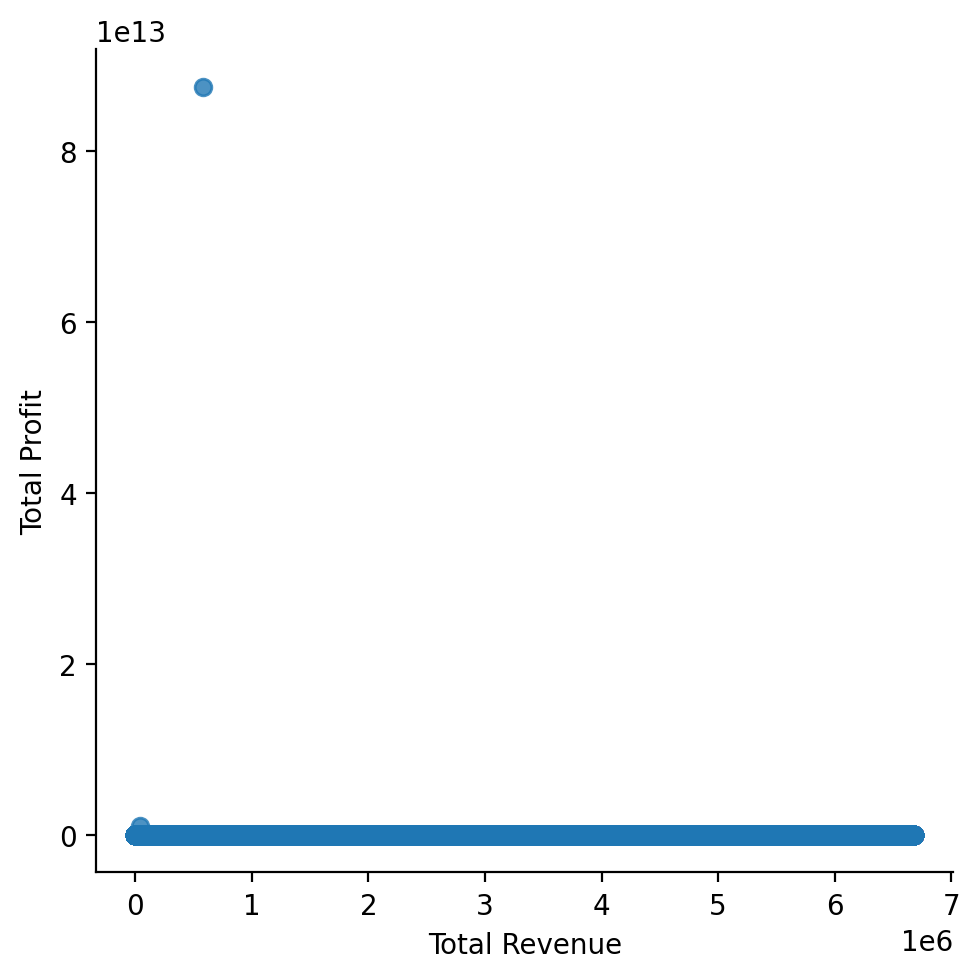

In [ ]:
#เราจะมา plot graph scatter plot เพื่อดูการกระจายของข้อมูลกัน โดยจะกำหนดแกน x เป็น 'Total revenue' และแกน y เป็น 'Total'
sns.lmplot(x = "Total Revenue", y = "Total Profit", data = data, ci= None)# CI = confident interval หรือช่วงความเชื่อมั่น
#จากกราฟจะเห็นว่ามีdata total profit ตัวหนึ่งกระโดดขึ้นสูงแบบผิดปกติ เราจะมาตรวจสอบมันกันครับ

In [ ]:
#เราจะมาหาสาเหตุกันว่า data ดังกล่าวคืออะไร โดยบอกให้โชว์ตัวที่ max ที่สุดมาซึ่งจะเห็นความผิดปกติคือค่ามากสุดของ Total Profit เพราะนี่มันเยอะมากจนติด e หรือ exponatial ที่มี 0 ถึง 6 ตัว
data.loc[data['Total Profit'].idxmax()]

,1500003
Region,Sub-Saharan Africa
Country,Ghana
Item_Type,Office Supplies
Sales Channel,NaN
Order Priority,L
Order_Date,3/23/2017
Order ID,601245963
Ship Date,4/15/2017
Units Sold,896
Unit Price,651.21


In [ ]:
#เรามาทดสอบว่ายอดเงินของ Total Profit มันสูงได้ขนาดนี้จริงๆ เลยเรียก Top 10 มาดู
data.sort_values("Total Profit", ascending = False).head(10)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1500003,Sub-Saharan Africa,Ghana,Office Supplies,NaN,L,3/23/2017,601245963,4/15/2017,896,651.21,524.96,583484.16,470364.16,8.750000e+13,1.499612e+10,good
1500005,Sub-Saharan Africa,Uganda,Personal Care,Online,M,6/19/2014,539471471,7/21/2014,451,81.73,56.67,36860.23,25558.17,1.000000e+12,2.712951e+09,good
1426741,Sub-Saharan Africa,Zambia,Cosmetics,Offline,C,6/30/2016,138959300,7/20/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good
275470,Sub-Saharan Africa,Senegal,Cosmetics,Online,M,2/18/2016,174407804,2/22/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good
619998,Central America and the Caribbean,Saint Vincent and the Grenadines,Cosmetics,Offline,C,2/11/2016,296771037,3/23/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good
342508,Sub-Saharan Africa,Comoros,Cosmetics,Online,H,6/20/2016,261322534,6/25/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good
80634,Europe,Romania,Cosmetics,Online,M,3/16/2016,707318103,5/3/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good
691631,Europe,Slovakia,Cosmetics,Online,M,4/29/2016,995501935,5/19/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good
583126,Asia,Maldives,Cosmetics,Online,H,4/11/2016,340228402,5/22/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good
1467797,Europe,Romania,Cosmetics,Online,M,3/17/2016,707318103,5/4/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good


In [ ]:
# แปลงตัวเลขได้ 8.750000*10^13
print(8.750000*(10**13))
#จากการที่เราเรียก top 10 มาดู มีเลขแปลกอยู่ 2 ค่าคือ Top 1,2 เราเลยจะลบมันออกไป


87500000000000.0


In [ ]:
# แปลงตัวเลขได้ 8.750000*10^13
print(8.750000*(10**13))
#จากการที่เราเรียก top 10 มาดู มีเลขแปลกอยู่ 2 ค่าคือ Top 1,2 เราเลยจะลบมันออกไป


87500000000000.0


In [ ]:
#จะเห็นว่าข้อมูลที่ผิดปกติ 2 ตัวดังกล่าวหายไปแล้ว
data.sort_values("Total Profit", ascending = False).head(3)


,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1500003,Sub-Saharan Africa,Ghana,Office Supplies,NaN,L,3/23/2017,601245963,4/15/2017,896,651.21,524.96,583484.16,470364.16,8.750000e+13,1.499612e+10,good
1500005,Sub-Saharan Africa,Uganda,Personal Care,Online,M,6/19/2014,539471471,7/21/2014,451,81.73,56.67,36860.23,25558.17,1.000000e+12,2.712951e+09,good
1426741,Sub-Saharan Africa,Zambia,Cosmetics,Offline,C,6/30/2016,138959300,7/20/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good


In [ ]:
#จะเห็นว่าข้อมูลที่ผิดปกติ 2 ตัวดังกล่าวหายไปแล้ว
data.sort_values("Total Profit", ascending = False).head(3)



,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1500003,Sub-Saharan Africa,Ghana,Office Supplies,NaN,L,3/23/2017,601245963,4/15/2017,896,651.21,524.96,583484.16,470364.16,8.750000e+13,1.499612e+10,good
1500005,Sub-Saharan Africa,Uganda,Personal Care,Online,M,6/19/2014,539471471,7/21/2014,451,81.73,56.67,36860.23,25558.17,1.000000e+12,2.712951e+09,good
1426741,Sub-Saharan Africa,Zambia,Cosmetics,Offline,C,6/30/2016,138959300,7/20/2016,10000,437.20,263.33,4372000.00,2633300.00,1.738700e+06,3.977000e+01,good


In [ ]:
#ต่อมาเช็ค Column Total Revenue
#เรามาทดสอบว่ายอดเงินของ Total Revunue  Top 5 มาดู
data.sort_values("Total Revenue", ascending = False).head(10)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1028057,Europe,Armenia,Household,Offline,H,4/26/2011,502635943,5/2/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1072947,Europe,Cyprus,Household,Online,M,7/23/2011,179003608,7/23/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1099878,Europe,Bosnia and Herzegovina,Household,Online,M,6/9/2011,790819776,7/7/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1216049,Central America and the Caribbean,Trinidad and Tobago,Household,Offline,H,2/15/2011,581541812,3/29/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1034026,Asia,Taiwan,Household,Offline,C,7/14/2011,301366841,8/19/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
142999,Sub-Saharan Africa,Senegal,Household,Online,C,2/24/2011,459178578,3/2/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
142998,Sub-Saharan Africa,Senegal,Household,Online,C,2/24/2011,459178578,3/2/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1085903,Europe,Sweden,Household,Offline,C,6/18/2011,668456542,7/31/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
859798,Sub-Saharan Africa,Comoros,Household,Online,L,6/27/2011,546093308,7/4/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
468659,Sub-Saharan Africa,Comoros,Household,Online,L,6/26/2011,546093308,7/3/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad


In [ ]:
#เรามาทดสอบว่ายอดเงินของ Total Revunue  Top 5 มาดู
data.sort_values("Total Revenue", ascending = False).head(10)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1028057,Europe,Armenia,Household,Offline,H,4/26/2011,502635943,5/2/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1072947,Europe,Cyprus,Household,Online,M,7/23/2011,179003608,7/23/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1099878,Europe,Bosnia and Herzegovina,Household,Online,M,6/9/2011,790819776,7/7/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1216049,Central America and the Caribbean,Trinidad and Tobago,Household,Offline,H,2/15/2011,581541812,3/29/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1034026,Asia,Taiwan,Household,Offline,C,7/14/2011,301366841,8/19/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
142999,Sub-Saharan Africa,Senegal,Household,Online,C,2/24/2011,459178578,3/2/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
142998,Sub-Saharan Africa,Senegal,Household,Online,C,2/24/2011,459178578,3/2/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
1085903,Europe,Sweden,Household,Offline,C,6/18/2011,668456542,7/31/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
859798,Sub-Saharan Africa,Comoros,Household,Online,L,6/27/2011,546093308,7/4/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad
468659,Sub-Saharan Africa,Comoros,Household,Online,L,6/26/2011,546093308,7/3/2011,10000,668.27,502.54,6682700.0,5025400.0,1657300.0,24.8,bad


In [ ]:
#ตัวสุดท้าย เราจะมา Check %margin ที่เราคำนวนเมื่อกี้ จะเห็นว่าบรรทัดแรก %margin ไม่ผิดปกติอะไร แต่ยอด Total Revenue - Total Cost มันผิดเพราะ Unit Sold x Unit price หรือ Unit Cost ก็ไม่ถึง
data.sort_values("%margin", ascending = False).head(10)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1500003,Sub-Saharan Africa,Ghana,Office Supplies,NaN,L,3/23/2017,601245963,4/15/2017,896,651.21,524.96,583484.16,470364.16,8.750000e+13,1.499612e+10,good
1500005,Sub-Saharan Africa,Uganda,Personal Care,Online,M,6/19/2014,539471471,7/21/2014,451,81.73,56.67,36860.23,25558.17,1.000000e+12,2.712951e+09,good
582889,Asia,Maldives,Clothes,Online,C,7/12/2016,766052043,7/21/2016,678,109.28,35.84,74091.84,24299.52,4.979232e+04,6.720000e+01,good
166345,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166344,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166338,Europe,Albania,Clothes,Offline,H,9/17/2016,469417321,10/9/2016,9872,109.28,35.84,1078812.16,353812.48,7.249997e+05,6.720000e+01,good
582878,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
582877,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
457834,Middle East and North Africa,Jordan,Clothes,Offline,M,8/18/2011,801217305,8/31/2011,6860,109.28,35.84,749660.80,245862.40,5.037984e+05,6.720000e+01,good
666574,Australia and Oceania,Kiribati,Clothes,Online,H,8/7/2012,838170421,8/25/2012,2108,109.28,35.84,230362.24,75550.72,1.548115e+05,6.720000e+01,good


In [ ]:
#ตัวสุดท้าย เราจะมา Check %margin ที่เราคำนวนเมื่อกี้ จะเห็นว่าบรรทัดแรก %margin ไม่ผิดปกติอะไร แต่ยอด Total Revenue - Total Cost มันผิดเพราะ Unit Sold x Unit price หรือ Unit Cost ก็ไม่ถึง
data.sort_values("%margin", ascending = False).head(10)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1500003,Sub-Saharan Africa,Ghana,Office Supplies,NaN,L,3/23/2017,601245963,4/15/2017,896,651.21,524.96,583484.16,470364.16,8.750000e+13,1.499612e+10,good
1500005,Sub-Saharan Africa,Uganda,Personal Care,Online,M,6/19/2014,539471471,7/21/2014,451,81.73,56.67,36860.23,25558.17,1.000000e+12,2.712951e+09,good
582889,Asia,Maldives,Clothes,Online,C,7/12/2016,766052043,7/21/2016,678,109.28,35.84,74091.84,24299.52,4.979232e+04,6.720000e+01,good
166345,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166344,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166338,Europe,Albania,Clothes,Offline,H,9/17/2016,469417321,10/9/2016,9872,109.28,35.84,1078812.16,353812.48,7.249997e+05,6.720000e+01,good
582878,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
582877,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
457834,Middle East and North Africa,Jordan,Clothes,Offline,M,8/18/2011,801217305,8/31/2011,6860,109.28,35.84,749660.80,245862.40,5.037984e+05,6.720000e+01,good
666574,Australia and Oceania,Kiribati,Clothes,Online,H,8/7/2012,838170421,8/25/2012,2108,109.28,35.84,230362.24,75550.72,1.548115e+05,6.720000e+01,good


In [ ]:
#ตัวสุดท้าย เราจะมา Check %margin ที่เราคำนวนเมื่อกี้ จะเห็นว่าบรรทัดแรก %margin ไม่ผิดปกติอะไร แต่ยอด Total Revenue - Total Cost มันผิดเพราะ Unit Sold x Unit price หรือ Unit Cost ก็ไม่ถึง
data.sort_values("%margin", ascending = False).head(10)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1500003,Sub-Saharan Africa,Ghana,Office Supplies,NaN,L,3/23/2017,601245963,4/15/2017,896,651.21,524.96,583484.16,470364.16,8.750000e+13,1.499612e+10,good
1500005,Sub-Saharan Africa,Uganda,Personal Care,Online,M,6/19/2014,539471471,7/21/2014,451,81.73,56.67,36860.23,25558.17,1.000000e+12,2.712951e+09,good
582889,Asia,Maldives,Clothes,Online,C,7/12/2016,766052043,7/21/2016,678,109.28,35.84,74091.84,24299.52,4.979232e+04,6.720000e+01,good
166345,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166344,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166338,Europe,Albania,Clothes,Offline,H,9/17/2016,469417321,10/9/2016,9872,109.28,35.84,1078812.16,353812.48,7.249997e+05,6.720000e+01,good
582878,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
582877,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
457834,Middle East and North Africa,Jordan,Clothes,Offline,M,8/18/2011,801217305,8/31/2011,6860,109.28,35.84,749660.80,245862.40,5.037984e+05,6.720000e+01,good
666574,Australia and Oceania,Kiribati,Clothes,Online,H,8/7/2012,838170421,8/25/2012,2108,109.28,35.84,230362.24,75550.72,1.548115e+05,6.720000e+01,good


In [ ]:
#ตัวสุดท้าย เราจะมา Check %margin ที่เราคำนวนเมื่อกี้ จะเห็นว่าบรรทัดแรก %margin ไม่ผิดปกติอะไร แต่ยอด Total Revenue - Total Cost มันผิดเพราะ Unit Sold x Unit price หรือ Unit Cost ก็ไม่ถึง
data.sort_values("%margin", ascending = False).head(10)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision
1500003,Sub-Saharan Africa,Ghana,Office Supplies,NaN,L,3/23/2017,601245963,4/15/2017,896,651.21,524.96,583484.16,470364.16,8.750000e+13,1.499612e+10,good
1500005,Sub-Saharan Africa,Uganda,Personal Care,Online,M,6/19/2014,539471471,7/21/2014,451,81.73,56.67,36860.23,25558.17,1.000000e+12,2.712951e+09,good
582889,Asia,Maldives,Clothes,Online,C,7/12/2016,766052043,7/21/2016,678,109.28,35.84,74091.84,24299.52,4.979232e+04,6.720000e+01,good
166345,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166344,Middle East and North Africa,Oman,Clothes,Offline,M,7/3/2014,896135318,8/8/2014,5210,109.28,35.84,569348.80,186726.40,3.826224e+05,6.720000e+01,good
166338,Europe,Albania,Clothes,Offline,H,9/17/2016,469417321,10/9/2016,9872,109.28,35.84,1078812.16,353812.48,7.249997e+05,6.720000e+01,good
582878,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
582877,Sub-Saharan Africa,Namibia,Clothes,Online,M,6/30/2011,518306910,8/10/2011,7388,109.28,35.84,807360.64,264785.92,5.425747e+05,6.720000e+01,good
457834,Middle East and North Africa,Jordan,Clothes,Offline,M,8/18/2011,801217305,8/31/2011,6860,109.28,35.84,749660.80,245862.40,5.037984e+05,6.720000e+01,good
666574,Australia and Oceania,Kiribati,Clothes,Online,H,8/7/2012,838170421,8/25/2012,2108,109.28,35.84,230362.24,75550.72,1.548115e+05,6.720000e+01,good


In [ ]:
#ตัวอย่างนี้เราจะจัดการค่า Total Revenue ลงไป โดยการคำนวนใหม่ โดย Unit Price x Unit Sold เพราะมันสามารถคำนวนได้ เราจึงไม่ต้องแทนค่านั่นเอง
data["Total Revenue"] = (data["Units Sold"] * data["Unit Price"]).round(2)
data["Total Cost"] = (data["Units Sold"] * data["Unit Cost"]).round(2)
data["Total Profit"] = (data["Total Revenue"] - data["Total Cost"]).round(2)
data["%margin"] = ((data["Total Profit"] / data["Total Revenue"]) *100).round(2)


In [ ]:
#เรามาลองเช็คโดยใช้คำสั่ง .info จะเห็นว่าไม่มี Nan แล้ว
data.info

<bound method DataFrame.info of                                Region           Country        Item_Type  \
0                  Sub-Saharan Africa      South Africa           Fruits   
1                  Sub-Saharan Africa      South Africa           Fruits   
2        Middle East and North Africa           Morocco          Clothes   
3        Middle East and North Africa           Morocco          Clothes   
4               Australia and Oceania  Papua New Guinea             Meat   
...                               ...               ...              ...   
1500006            Sub-Saharan Africa          Zimbabwe  Office Supplies   
1500008         Australia and Oceania           Vanuatu           Fruits   
1500009                          Asia             India           Snacks   
1500012                          Asia            Brunei           Cereal   
1500013  Middle East and North Africa            Israel        Beverages   

        Sales Channel Order Priority  Order_Date   Order ID   Ship Date  \
0             Offline              M   7/27/2012  443368995   7/28/2012   
1             Offline              M   7/27/2012  443368995   7/28/2012   
2              Online              M   9/14/2013  667593514  10/19/2013   
3              Online              M   9/14/2013  667593514  10/19/2013   
4             Offline              M   5/15/2015  940995585    6/4/2015   
...               ...            ...         ...        ...         ...   
1500006       Offline              C   3/28/2011  953361213    4/8/2011   
1500008        Online              C   11/3/2013  571997869  11/11/2013   
1500009        Online              L  10/10/2012  440306556  11/20/2012   
1500012       Offline              L   5/28/2013  153842341   7/16/2013   
1500013       Offline              H    9/8/2013  371502530  10/13/2013   

         Units Sold  Unit Price  Unit Cost  Total Revenue  Total Cost  \
0              1593        9.33       6.92       14862.69    11023.56   
1              1593        9.33       6.92       14862.69    11023.56   
2              4611      109.28      35.84      503890.08   165258.24   
3              4611      109.28      35.84      503890.08   165258.24   
4               360      421.89     364.69      151880.40   131288.40   
...             ...         ...        ...            ...         ...   
1500006        9623      651.21     524.96     6266593.83  5051690.08   
1500008        5735        9.33       6.92       53507.55    39686.20   
1500009        5349      152.58      97.44      816150.42   521206.56   
1500012        4222      205.70     117.11      868465.40   494438.42   
1500013        4709       47.45      31.79      223442.05   149699.11   

         Total Profit  %margin dicision  
0             3839.13    25.83      bad  
1             3839.13    25.83      bad  
2           338631.84    67.20     good  
3           338631.84    67.20     good  
4            20592.00    13.56      bad  
...               ...      ...      ...  
1500006    1214903.75    19.39      bad  
1500008      13821.35    25.83      bad  
1500009     294943.86    36.14      bad  
1500012     374026.98    43.07      bad  
1500013      73742.94    33.00      bad  

[1500008 rows x 16 columns]>

In [ ]:
#เช็คอีกครั้งด้วยคำสั่ง .isnull.sum()
data.isnull().sum()

,0
Region,1
Country,0
Item_Type,0
Sales Channel,1
Order Priority,0
Order_Date,0
Order ID,0
Ship Date,0
Units Sold,0
Unit Price,0


In [ ]:
#ต่อมา เราจะมาเพิ่ม Columns ใหม่ชื่อว่า Year เอาไว้วิเคราะห์เชิงลึก โดยแยกตาก Columns ที่ชื่อว่า "Order_Date" ดังนี้
data['year'] = pd.DatetimeIndex(data['Order_Date']).year

In [ ]:
#ต่อมา เราจะมาเพิ่ม Columns ใหม่ชื่อว่า Month เอาไว้วิเคราะห์เชิงลึก โดยแยกตาก Columns ที่ชื่อว่า "Order_Date" ดังนี้
data['month'] = pd.DatetimeIndex(data['Order_Date']).month

In [ ]:
#เปลี่ยนชื่อ Month ให้ดูดีขึ้น โดยใช้คำสั่ง .replace ช่วย
data = data.replace({"month":{
    1 : "1.January",
    2 : "2.Febuary",
    3 : "3.March",
    4 : "4.April",
    5 : "5.May",
    6 : "6.June",
    7 : "7.July",
    8 : "8.August",
    9 : "9.September",
    10 : "10.October",
    11 : "11.November",
    12 : "12.December"
}})
#จุดสำคัญในการเขียนโปรแกรมคือ "ระวังการเติมเครื่องหมายไม่ครบ เช่น { และคู่ของมันหาย เป็นต้น"



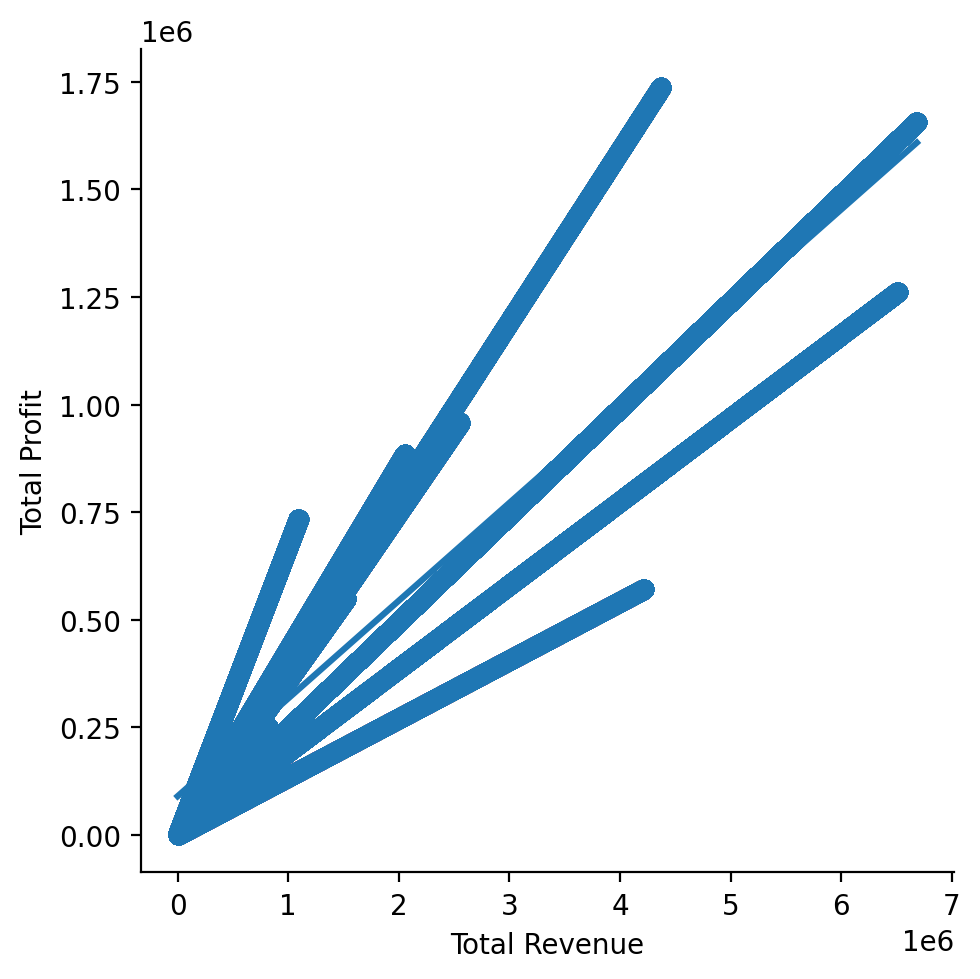

In [ ]:
#เมื่อ Clean พวก Anomaly data แล้ว เราลอง plot grap มาตรวจสอบอีกรอบ จะเห็นถึงความสัมพันธ์ของ 2 ตัวแปรที่ชัดเจนมากขึ้น
sns.lmplot(x = "Total Revenue", y = "Total Profit", data = data, ci= None)


In [ ]:
#เราจะมาทำการ Sort Data ของเรามาดู โดดยเราจะใช้คำสั่ง .sort.value
data.sort_values("Total Profit", ascending = True) # ascending เป็นตัวที่จะกำหนดว่าใช้กรองจากน้อยไปมาก หรือ มากไปน้อย ในที่นี้กำหนดให้เรียง  Total Profit จากน้อยไปมาก จึงใช้ ascending = True


,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision,year,month
576730,Central America and the Caribbean,Honduras,Fruits,Online,M,6/22/2013,289944922,8/11/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,6.June
1239029,Asia,China,Fruits,Offline,L,7/10/2013,945218455,8/7/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,7.July
576729,Central America and the Caribbean,Honduras,Fruits,Online,M,6/22/2013,289944922,8/11/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,6.June
965759,Sub-Saharan Africa,Malawi,Fruits,Offline,C,5/18/2013,779397857,6/29/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,5.May
1016058,Europe,Luxembourg,Fruits,Offline,L,6/14/2013,412308156,7/19/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,6.June
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
829606,Europe,Armenia,Cosmetics,Offline,C,4/21/2016,217865169,4/26/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,4.April
1426741,Sub-Saharan Africa,Zambia,Cosmetics,Offline,C,6/30/2016,138959300,7/20/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,6.June
1467797,Europe,Romania,Cosmetics,Online,M,3/17/2016,707318103,5/4/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,3.March
1180739,Europe,Sweden,Cosmetics,Offline,L,6/12/2016,383685767,7/24/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,6.June


In [ ]:
#ต่อมาลองกำหนดให้เรียง Total Profit จาก มากไปน้อย
data.sort_values("Total Profit", ascending = False)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision,year,month
969307,Sub-Saharan Africa,South Sudan,Cosmetics,Offline,L,4/3/2016,462591636,4/30/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,4.April
691631,Europe,Slovakia,Cosmetics,Online,M,4/29/2016,995501935,5/19/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,4.April
897995,Asia,Maldives,Cosmetics,Online,H,4/12/2016,340228402,5/23/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,4.April
1218962,Sub-Saharan Africa,Botswana,Cosmetics,Offline,C,3/25/2016,584954869,4/6/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,3.March
275470,Sub-Saharan Africa,Senegal,Cosmetics,Online,M,2/18/2016,174407804,2/22/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,2.Febuary
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
492352,Asia,Bhutan,Fruits,Online,M,5/27/2013,657034623,6/2/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,5.May
669807,Central America and the Caribbean,Grenada,Fruits,Online,H,5/10/2013,901761090,6/7/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,5.May
470541,Europe,Monaco,Fruits,Offline,C,7/27/2013,700491988,8/2/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,7.July
576729,Central America and the Caribbean,Honduras,Fruits,Online,M,6/22/2013,289944922,8/11/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,6.June


In [ ]:
#ต่อมาลองกำหนดให้เรียง Total Profit จาก มากไปน้อย
data.sort_values("Total Profit", ascending = False)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision,year,month
969307,Sub-Saharan Africa,South Sudan,Cosmetics,Offline,L,4/3/2016,462591636,4/30/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,4.April
691631,Europe,Slovakia,Cosmetics,Online,M,4/29/2016,995501935,5/19/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,4.April
897995,Asia,Maldives,Cosmetics,Online,H,4/12/2016,340228402,5/23/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,4.April
1218962,Sub-Saharan Africa,Botswana,Cosmetics,Offline,C,3/25/2016,584954869,4/6/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,3.March
275470,Sub-Saharan Africa,Senegal,Cosmetics,Online,M,2/18/2016,174407804,2/22/2016,10000,437.20,263.33,4372000.00,2633300.00,1738700.00,39.77,good,2016,2.Febuary
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
492352,Asia,Bhutan,Fruits,Online,M,5/27/2013,657034623,6/2/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,5.May
669807,Central America and the Caribbean,Grenada,Fruits,Online,H,5/10/2013,901761090,6/7/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,5.May
470541,Europe,Monaco,Fruits,Offline,C,7/27/2013,700491988,8/2/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,7.July
576729,Central America and the Caribbean,Honduras,Fruits,Online,M,6/22/2013,289944922,8/11/2013,1,9.33,6.92,9.33,6.92,2.41,25.83,bad,2013,6.June


In [ ]:
#เราจะเริ่มมาทำการวิเคราะห์ข้อมูลกันแล้วนะครับ โดยเริ่มทำการวิเคราะห์ โดยเรียงข้อมูลโดยใช้ %margin ดูจะเห็นว่า Region = Middle East และ Country = Israel สูงที่สุด
data.sort_values("%margin", ascending = False)

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision,year,month
1499978,Australia and Oceania,Nauru,Clothes,Online,C,1/24/2013,133836066,2/19/2013,3921,109.28,35.84,428486.88,140528.64,287958.24,67.20,good,2013,1.January
20,Australia and Oceania,Papua New Guinea,Clothes,Offline,L,6/20/2011,647164094,7/14/2011,9092,109.28,35.84,993573.76,325857.28,667716.48,67.20,good,2011,6.June
19,Australia and Oceania,Papua New Guinea,Clothes,Offline,L,6/20/2011,647164094,7/14/2011,9092,109.28,35.84,993573.76,325857.28,667716.48,67.20,good,2011,6.June
1499956,Middle East and North Africa,Syria,Clothes,Online,M,4/13/2011,565764844,4/26/2011,1245,109.28,35.84,136053.60,44620.80,91432.80,67.20,good,2011,4.April
1499945,Sub-Saharan Africa,Lesotho,Clothes,Online,L,1/8/2013,731564843,1/12/2013,5149,109.28,35.84,562682.72,184540.16,378142.56,67.20,good,2013,1.January
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1375097,Middle East and North Africa,Tunisia,Meat,Online,C,5/27/2014,359209430,6/17/2014,6908,421.89,364.69,2914416.12,2519278.52,395137.60,13.56,bad,2014,5.May
1375103,Europe,Germany,Meat,Online,M,5/14/2015,226332366,5/22/2015,5632,421.89,364.69,2376084.48,2053934.08,322150.40,13.56,bad,2015,5.May
11330,Sub-Saharan Africa,Cameroon,Meat,Offline,H,3/14/2011,867008244,3/31/2011,5861,421.89,364.69,2472697.29,2137448.09,335249.20,13.56,bad,2011,3.March
1375084,North America,United States of America,Meat,Offline,H,1/27/2012,859404504,2/14/2012,5745,421.89,364.69,2423758.05,2095144.05,328614.00,13.56,bad,2012,1.January


In [ ]:
#เราจะมา sum ข้อมูลทั้งหมดกันก่อน โดย sum Columns Total Profit
Total_Amount = data["Total Profit"].sum().round(2)
Total_Amount

np.float64(588603350862.71)

In [ ]:
#จากเมื่อกี้ที่เราเห็นว่า Middel East มี Magin สูงสุด มี Profit เท่าไร
Middle_East_Amount = data["Total Profit"][data["Region"] == "Middle East and North Africa"].sum().round(2)
Middle_East_Amount

np.float64(73093917891.11)

In [ ]:
#หรือสามารถสร้างเป็นประโยคก็ได้ โดยใช้ "" ใส่คำพูด และเชื่อมคำด้วย + เช่น (จาก Code ผมใส่ str ไปเพื่อบอกว่า ข้อมูลตัวนี้คือ string หรือคำพูด เพราะถ้าไม่ใส่มันจะเป็นข้อมูลตัวเลขหรือ Numerical ซึ่งการบวกตัวเลขกับตัวอักษรมันจะ Error)
print("Middle East มี Total Profit : " + str(Middle_East_Amount) + " บาท คิดเป็น : " + str(((Middle_East_Amount/Total_Amount).round(2))*100)+ "% ของทั้งหมด")


Middle East มี Total Profit : 73093917891.11 บาท คิดเป็น : 12.0% ของทั้งหมด


In [ ]:
#มาลองวิเคราะห์ตัวอื่นๆกันครับ
data["Total Profit"][data["Country"] == "Iraq"].sum()


np.float64(3159373979.71)

In [ ]:
# .count นี้เป็นการนับจำนวน
data["Total Profit"][data["Country"] == "Iraq"].count()

np.float64(390721.49143086816)

In [ ]:
# .min เป็นการดูค่าต่ำสุด
data["Total Profit"][data["Country"] == "Iraq"].min()

33.74

In [ ]:
# .mean เป็นการดูค่าเฉลี่ย
data["Total Profit"][data["Country"] == "Iraq"].mean()

np.float64(390721.49143086816)

In [ ]:
#เราสามารถใส่ทศนิยมให้เท่ๆ โดย .apply(lambda x : "{:,}".format(x))
data["Total Profit"][data["Country"] == "Iraq"].apply(lambda x : "{:,}".format(x)) #ใส่ทศนิยมให้เท่ๆ


,Total Profit
268,"87,058.44"
740,"7,348.09"
741,"7,348.09"
1399,"683,206.08"
1400,"683,206.08"
...,...
1498512,"1,433,730.23"
1498890,"566,051.2"
1499277,"83,530.44"
1499721,"892,300.84"


In [ ]:
#Groupby เป็น Function หนึ่งที่ทำงานคล้าย Sumif และจพแสดงออกมาคล้ายๆ Pivot Table ดังตัวอย่างต่อไปนี้
data.groupby(["year","month","Item_Type","Order ID"]).sum() #ตัวอย่างนี้ ตัวแปรที่ใส่คือหมายความว่า ไม่ต้องเอาไป Sum นั่นเอง



Region  \
year month     Item_Type  Order ID                                          
2010 1.January Baby Food  101137149                 Australia and Oceania   
                          101335847                    Sub-Saharan Africa   
                          102081286                                  Asia   
                          102279984                 Australia and Oceania   
                          103224122                                  Asia   
...                                                                   ...   
2017 7.July    Vegetables 994640195                                  Asia   
                          995506656                                Europe   
                          995783030                                  Asia   
                          996804845  Sub-Saharan AfricaSub-Saharan Africa   
                          999913632                    Sub-Saharan Africa   

                                                Country Sales Channel  \
year month     Item_Type  Order ID                                      
2010 1.January Baby Food  101137149          East Timor        Online   
                          101335847              Rwanda        Online   
                          102081286            Cambodia       Offline   
                          102279984            Kiribati        Online   
                          103224122               India        Online   
...                                                 ...           ...   
2017 7.July    Vegetables 994640195           Sri Lanka        Online   
                          995506656             Ukraine        Online   
                          995783030              Taiwan       Offline   
                          996804845  SwazilandSwaziland  OnlineOnline   
                          999913632               Ghana       Offline   

                                    Order Priority         Order_Date  \
year month     Item_Type  Order ID                                      
2010 1.January Baby Food  101137149              H          1/10/2010   
                          101335847              H          1/29/2010   
                          102081286              C           1/5/2010   
                          102279984              H          1/25/2010   
                          103224122              C          1/20/2010   
...                                            ...                ...   
2017 7.July    Vegetables 994640195              M          7/10/2017   
                          995506656              C          7/15/2017   
                          995783030              M          7/24/2017   
                          996804845             LL  7/9/20177/10/2017   
                          999913632              L           7/5/2017   

                                              Ship Date  Units Sold  \
year month     Item_Type  Order ID                                    
2010 1.January Baby Food  101137149           1/27/2010        7585   
                          101335847            3/9/2010        6384   
                          102081286           1/22/2010        6976   
                          102279984            3/6/2010        5775   
                          103224122            3/1/2010        5166   
...                                                 ...         ...   
2017 7.July    Vegetables 994640195           8/28/2017        4992   
                          995506656            8/7/2017        1397   
                          995783030           8/14/2017        3182   
                          996804845  8/27/20178/28/2017       11120   
                          999913632           8/23/2017        5519   

                                     Unit Price  Unit Cost  Total Revenue  \
year month     Item_Type  Order ID                                          
2010 1.January Baby Food  101137149      255.28     159.42     1936298.80   
          

In [ ]:
data.groupby(["month"])["Total Profit"].sum().round(2)

,Total Profit
month,
1.January,5.262556e+10
10.October,4.588399e+10
11.November,4.490212e+10
12.December,4.626535e+10
2.Febuary,4.782907e+10
3.March,5.281886e+10
4.April,5.113972e+10
5.May,5.280839e+10
6.June,5.111820e+10


In [ ]:
#เราสามารถแยกดูเป็นรายตัวก็ได้ ตัวอย่างนี้ผมต้องการดูแค่ Country และ Item Type โดยไป sum ที่ Total Profit
data.groupby(["Country","Item_Type"])["Total Profit"].sum()

Country      Item_Type      
Afghanistan  Baby Food          3.318292e+08
             Beverages          5.207576e+07
             Cereal             2.911936e+08
             Clothes            2.400776e+08
             Cosmetics          5.684838e+08
                                    ...     
Zimbabwe     Meat               1.907654e+08
             Office Supplies    4.377148e+08
             Personal Care      8.798709e+07
             Snacks             1.870779e+08
             Vegetables         2.121591e+08
Name: Total Profit, Length: 2220, dtype: float64

In [ ]:
#ข้อมูลอาจดูยาก ผมเลยใช้ function round และ ใส่ , มาช่วย
data.groupby(["Country","Item_Type"])["Total Profit"].sum().round(2).apply(lambda x : "{:,}".format(x))


Country      Item_Type      
Afghanistan  Baby Food          331,829,167.72
             Beverages            52,075,764.0
             Cereal             291,193,646.79
             Clothes            240,077,636.64
             Cosmetics          568,483,787.17
                                     ...      
Zimbabwe     Meat                190,765,432.0
             Office Supplies     437,714,810.0
             Personal Care       87,987,088.42
             Snacks              187,077,889.2
             Vegetables          212,159,097.1
Name: Total Profit, Length: 2220, dtype: object

In [ ]:
#ผมสามารถ Export ออกมาเป็น excel ก็ได้นะ โดยใช้คำสั่ง to_excel ดังนี้
#1.อันดับแรก ผมตั้งชื่อตัวแปรว่า export ก่อนจะได้ไม่ต้องพิมพ์ Code หมด
export = data.groupby(["Country","Item_Type"])["Total Profit"].sum().round(2).apply(lambda x : "{:,}".format(x))
#2.เริ่ม Export โดยใช้ Function to_excel

export.to_excel("file.xlsx") #ตั้งชื่อว่า export คือ data ที่จะเอาไปลง Excel ส่วน file คือชื่อที่เราตั้ง


<Axes: xlabel='Total Revenue', ylabel='Total Profit'>

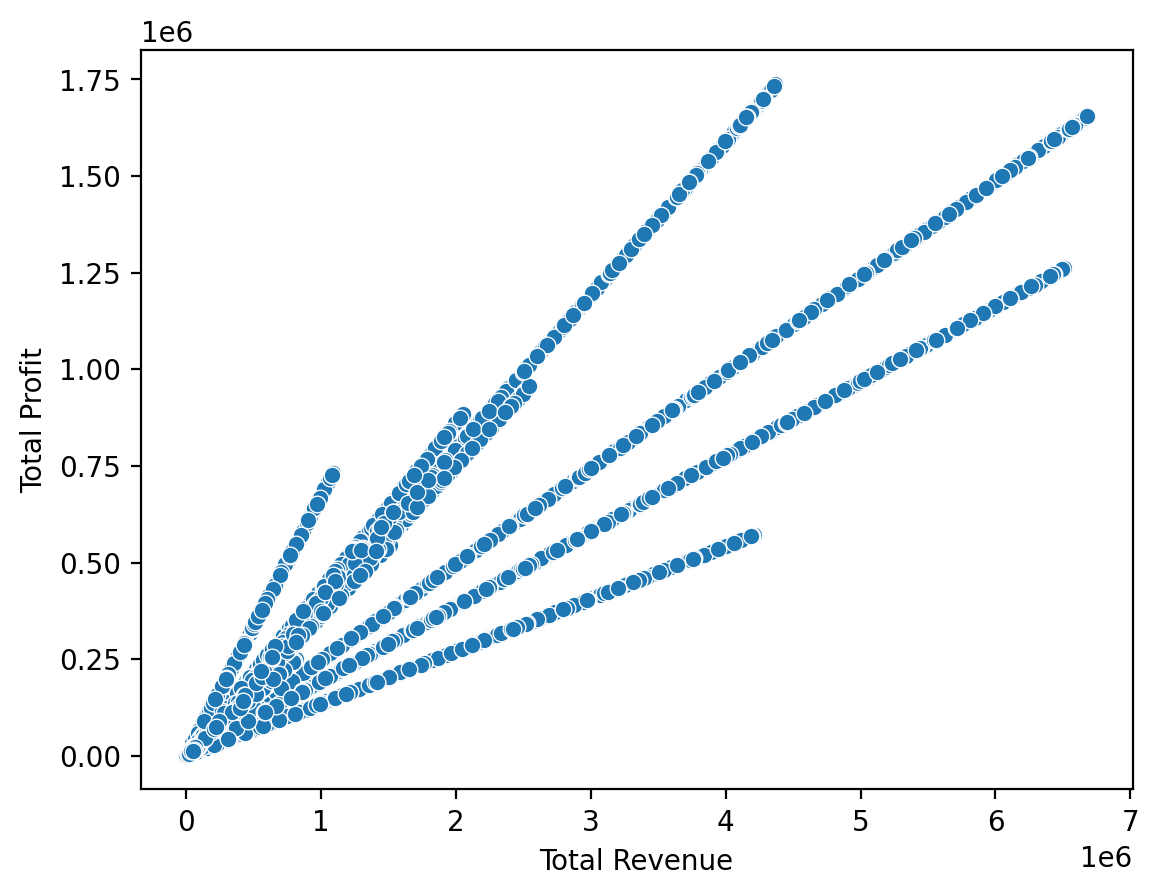

In [ ]:
#Data Visulization

#หลังจากที่เรา Analysis แล้วเราจะมา Visualization กันโดยใช้กราฟรูปแบบต่างๆ ดังนี้ครับ
#1.อันดับแรก เราจะใช้ scatter plot ในการดูการกระจายของข้อมูล และความสัมพันธ์ของข้อมูล ซึ่งจากภาพจะเห็นว่าข้อมูลค่อนข้างสัมพันธ์กัน พูดง่ายๆคือ ถ้า X หรือ Revenue มาก y หรือ Profit จะมากตามนั่นเอง
sns.scatterplot(x = "Total Revenue", y = "Total Profit", data = data)

<Axes: xlabel='month', ylabel='Total Profit'>

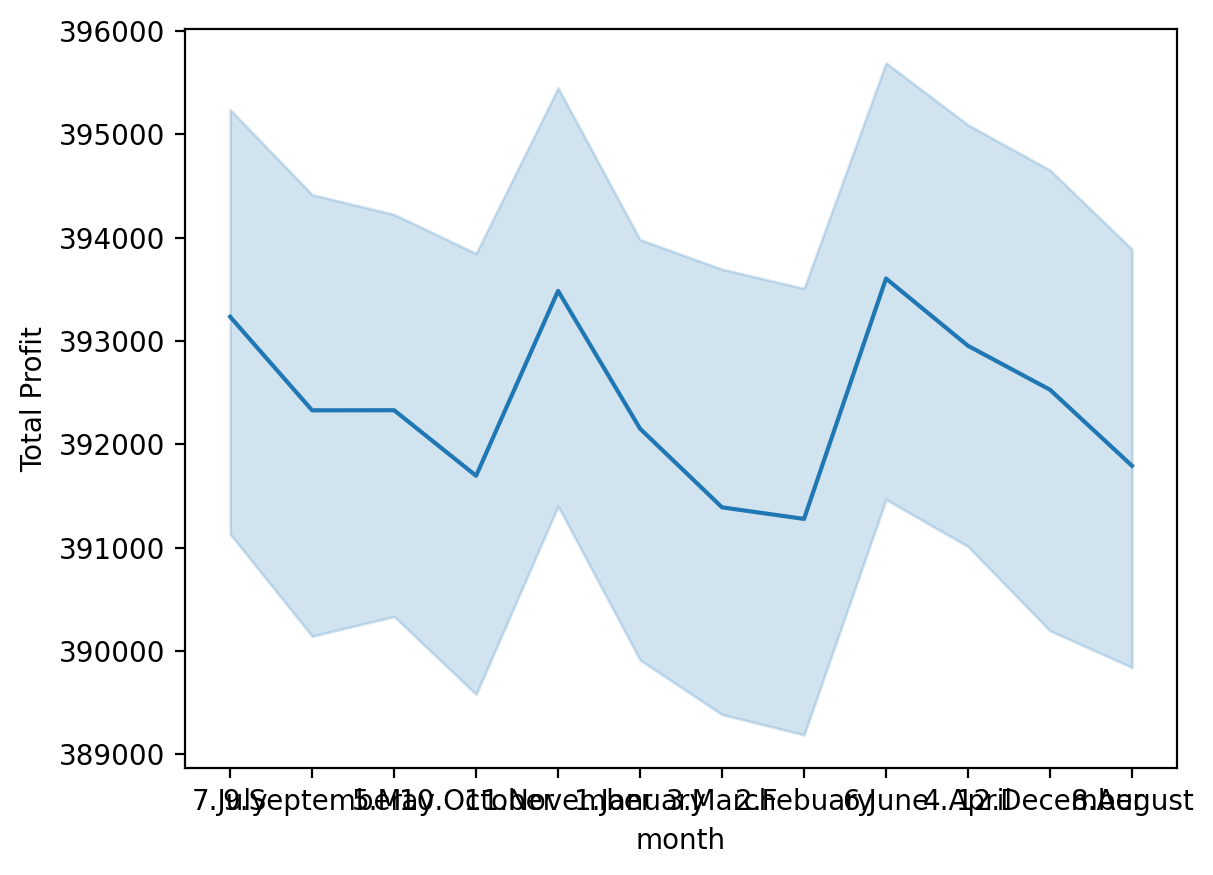

In [ ]:
#กราฟต่อมา มาลองทำเป็น Line plot
#การใช้ Line plot ส่วนใหญ่จะเป็นการใช้เพื่อดูแนวโน้ม ตัวอย่างนี้ผมจะดูแนวโน้มการเคลื่อนไหวของ Profit ในแต่ละเดือน
sns.lineplot(x = "month", y = "Total Profit", data = data)

<Axes: xlabel='month', ylabel='Total Profit'>

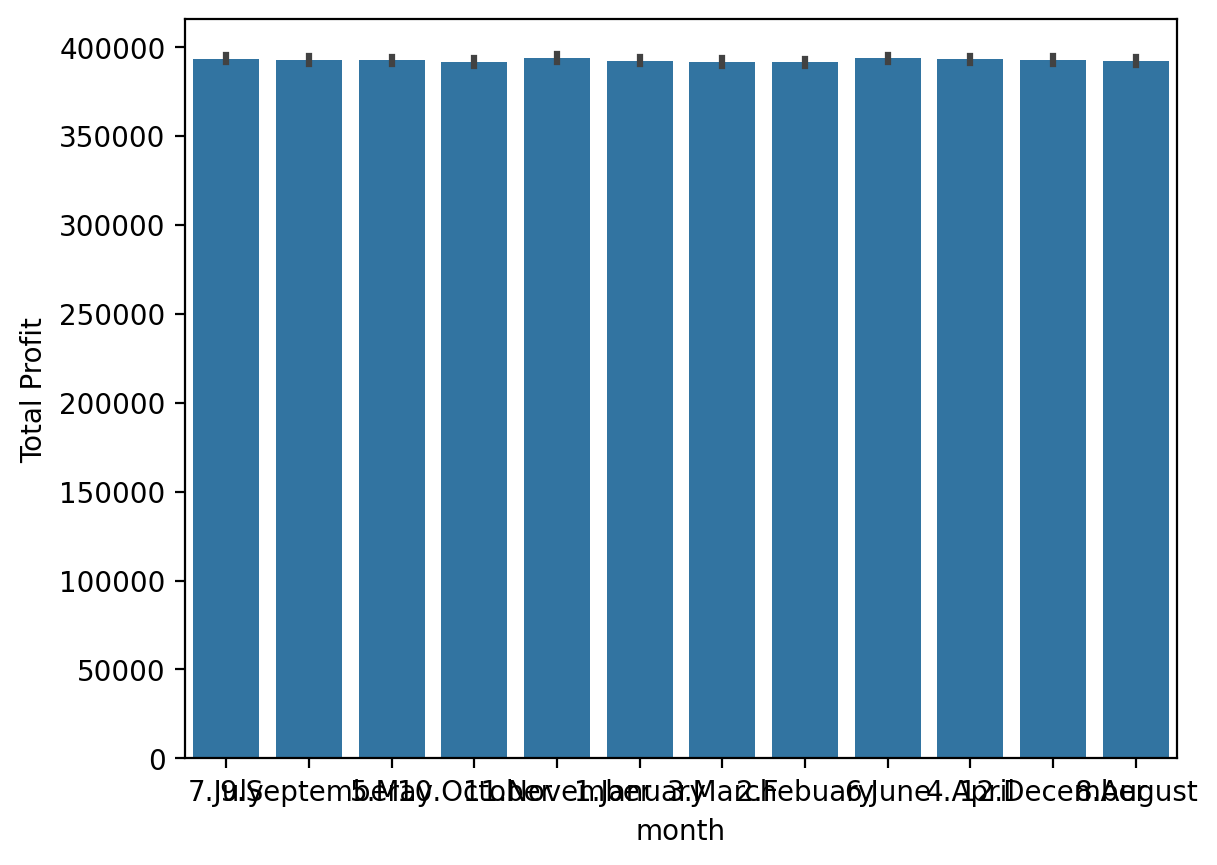

In [ ]:
#กราฟต่อมา มาลองทำเป็น Bar plot
#การใช้ Bar plot ส่วนใหญ่จะเป็นการใช้เพื่อดูเพื่อเปรียบเทียบ ตัวอย่างนี้ผมจะดู Profit ในแต่ละเดือนเทียบกัน
sns.barplot(x = "month", y = "Total Profit", data = data)


<Axes: xlabel='year', ylabel='%margin'>

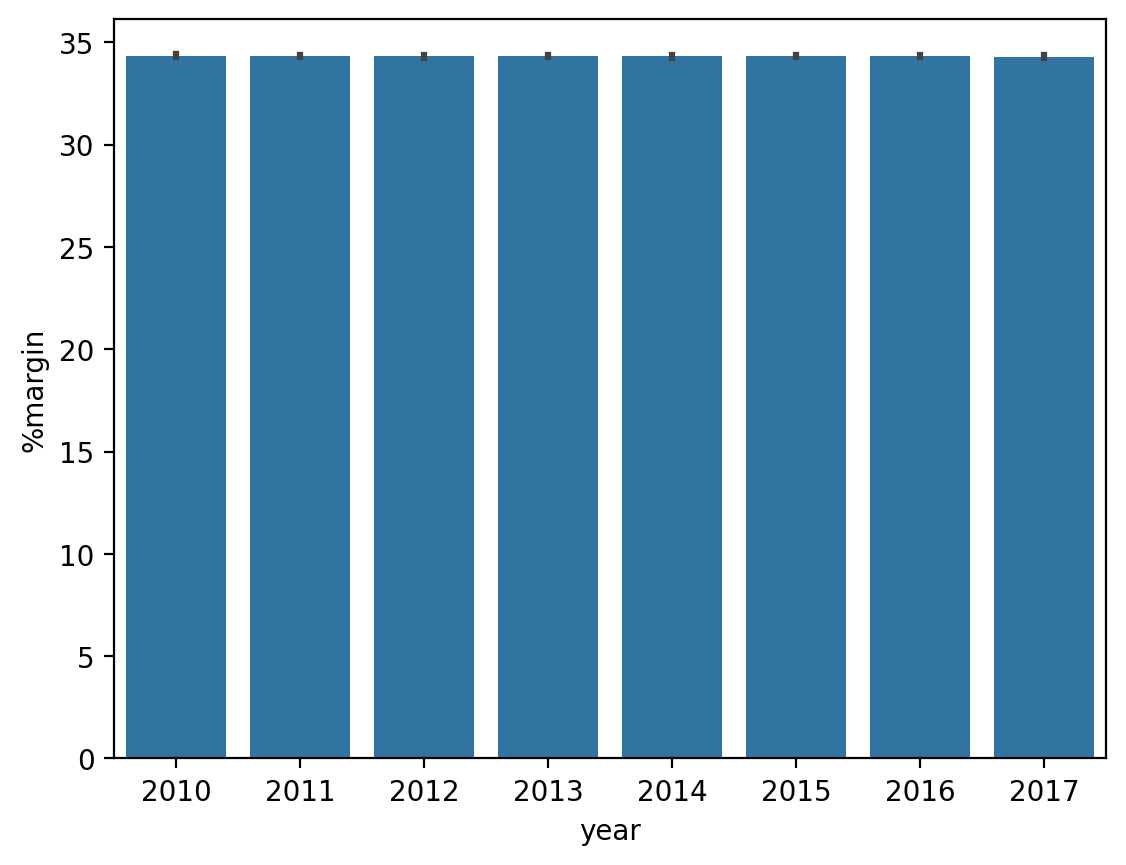

In [ ]:
sns.barplot(x = "year", y = "%margin", data = data)

<Axes: xlabel='year', ylabel='%margin'>

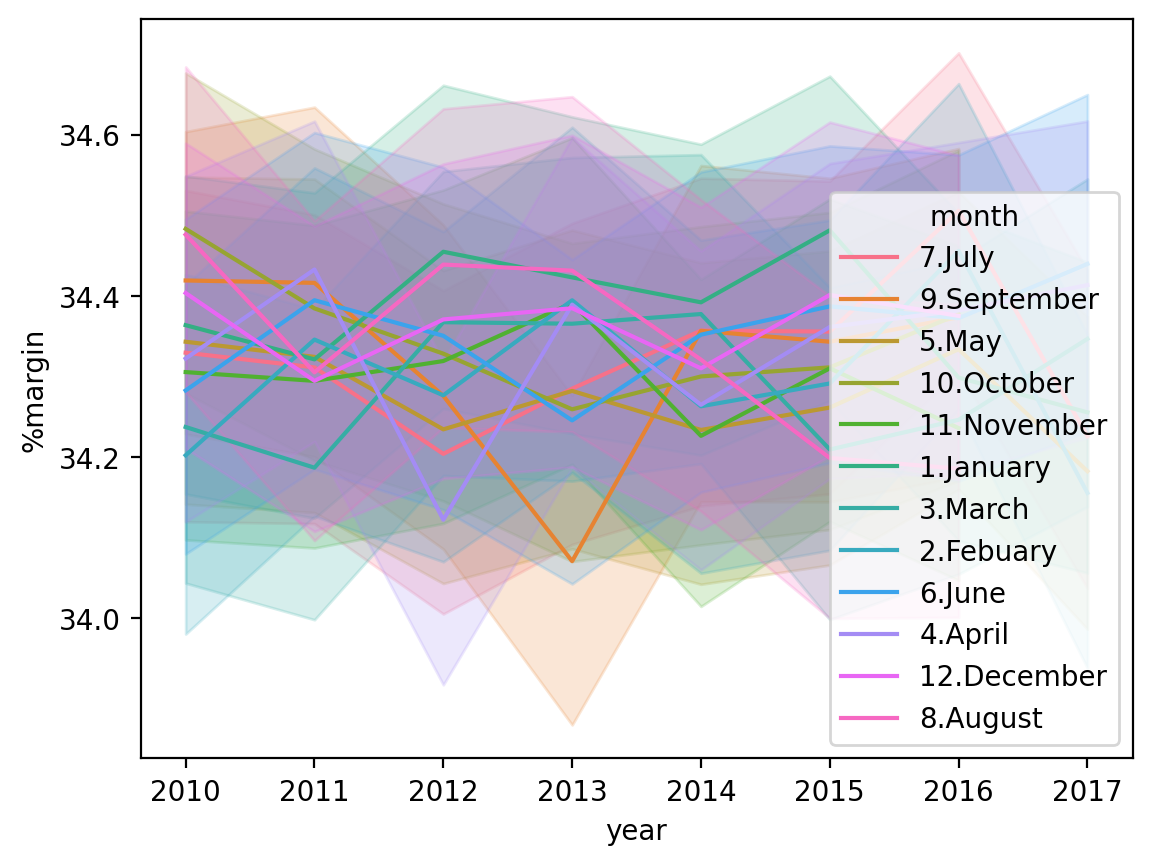

In [ ]:
sns.lineplot(x = "year", y = "%margin", hue =  "month",data = data)

In [ ]:
#จากหลายๆกราฟ จะเห็นได้ว่ากราฟมีขนาดค่อนข้างเล็ก ดูยาก เราจะมาปีับกราฟให้ใหญ่ขึ้นโดยใช้ code ดังกล่าว
sns.set(rc={'figure.figsize':(10,8.24)}) # เรามาขยายรูปกันเถอะ!!

<Axes: xlabel='year', ylabel='%margin'>

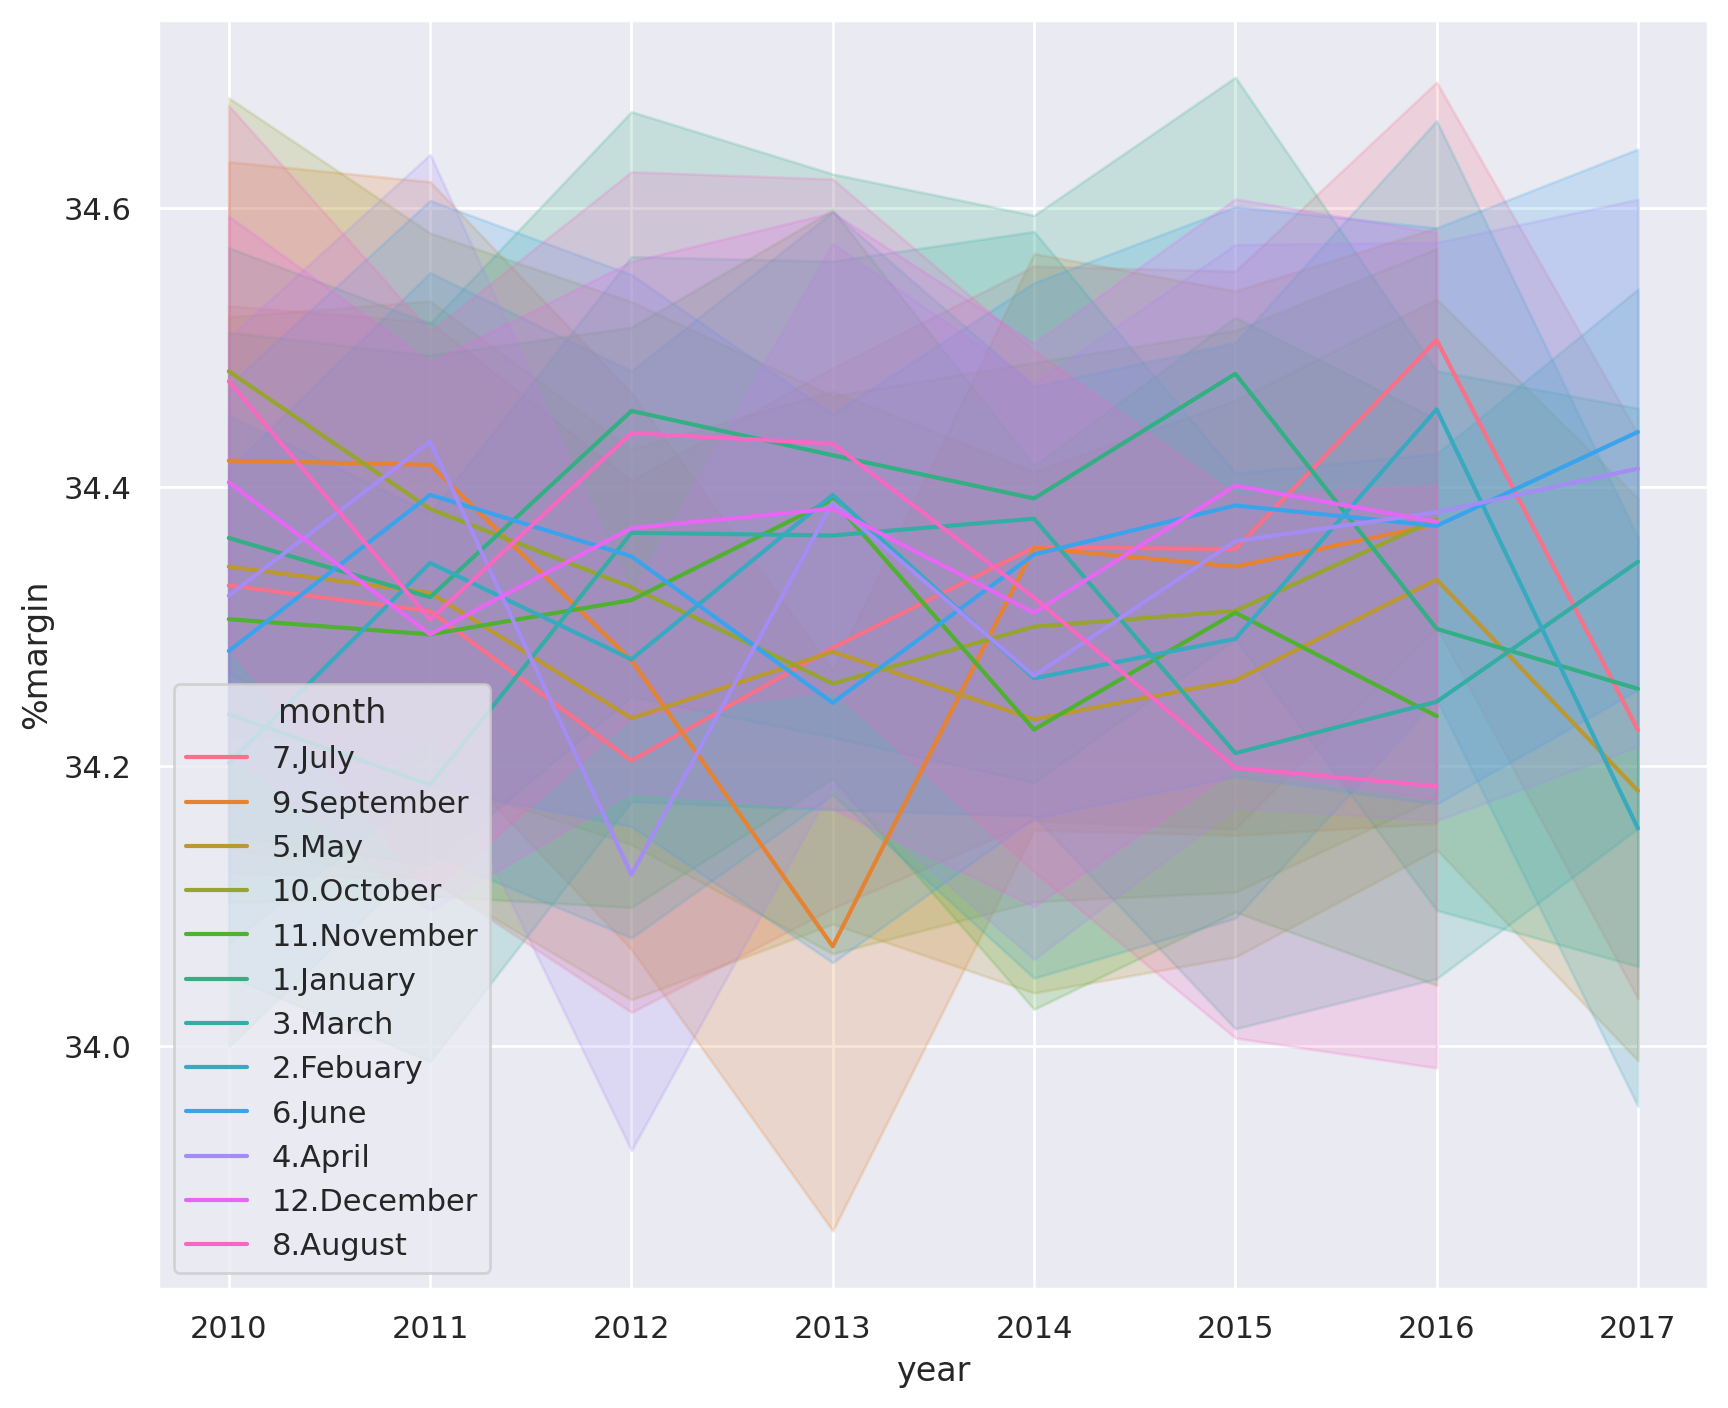

In [ ]:
#จะเห็นว่าดูใหญ่ขึ้นมาก
sns.lineplot(x = "year", y = "%margin", hue =  "month",data = data)

<Axes: xlabel='year', ylabel='%margin'>

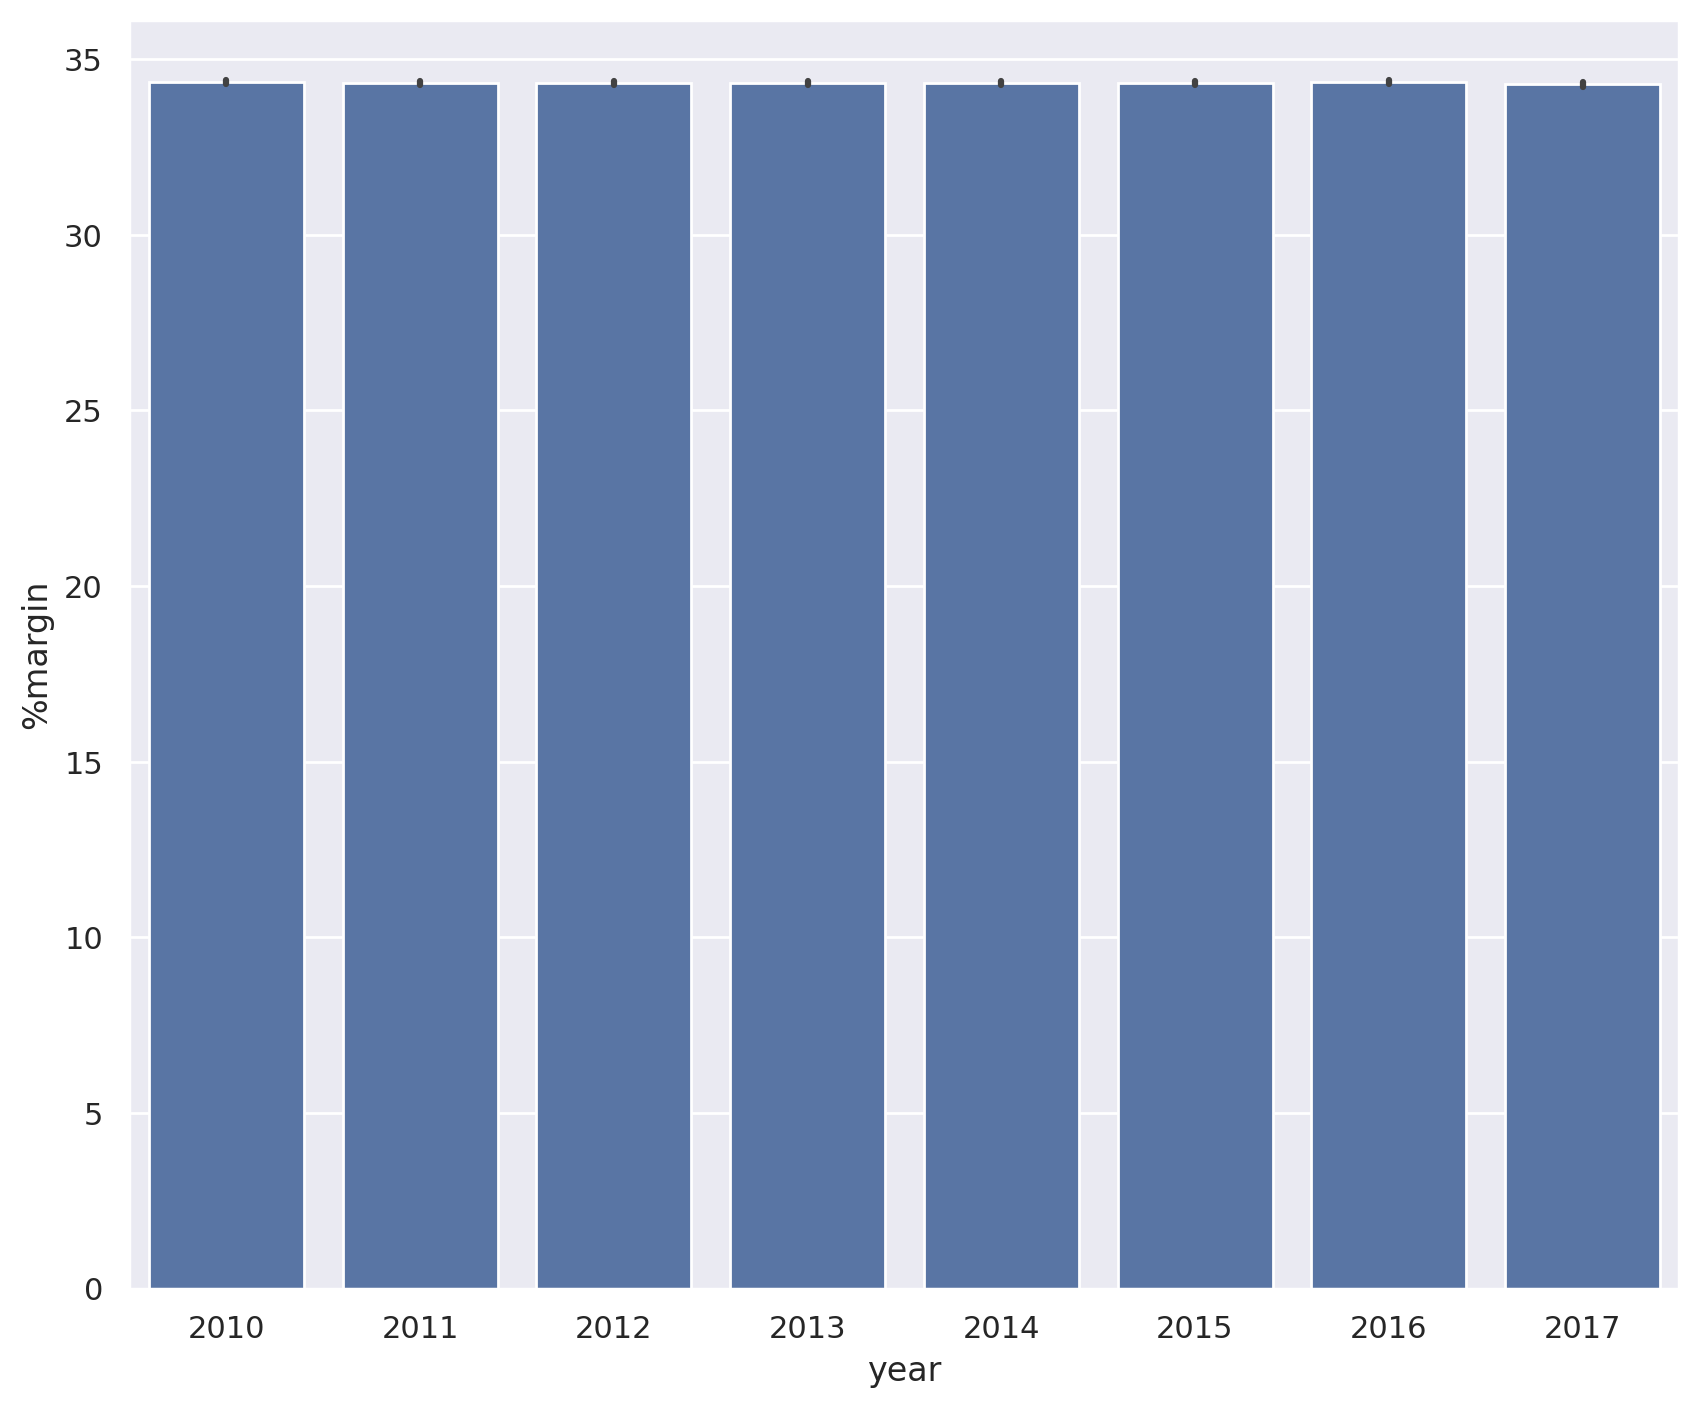

In [ ]:
sns.barplot(x = "year", y = "%margin", data = data)

<Axes: xlabel='year', ylabel='Total Profit'>

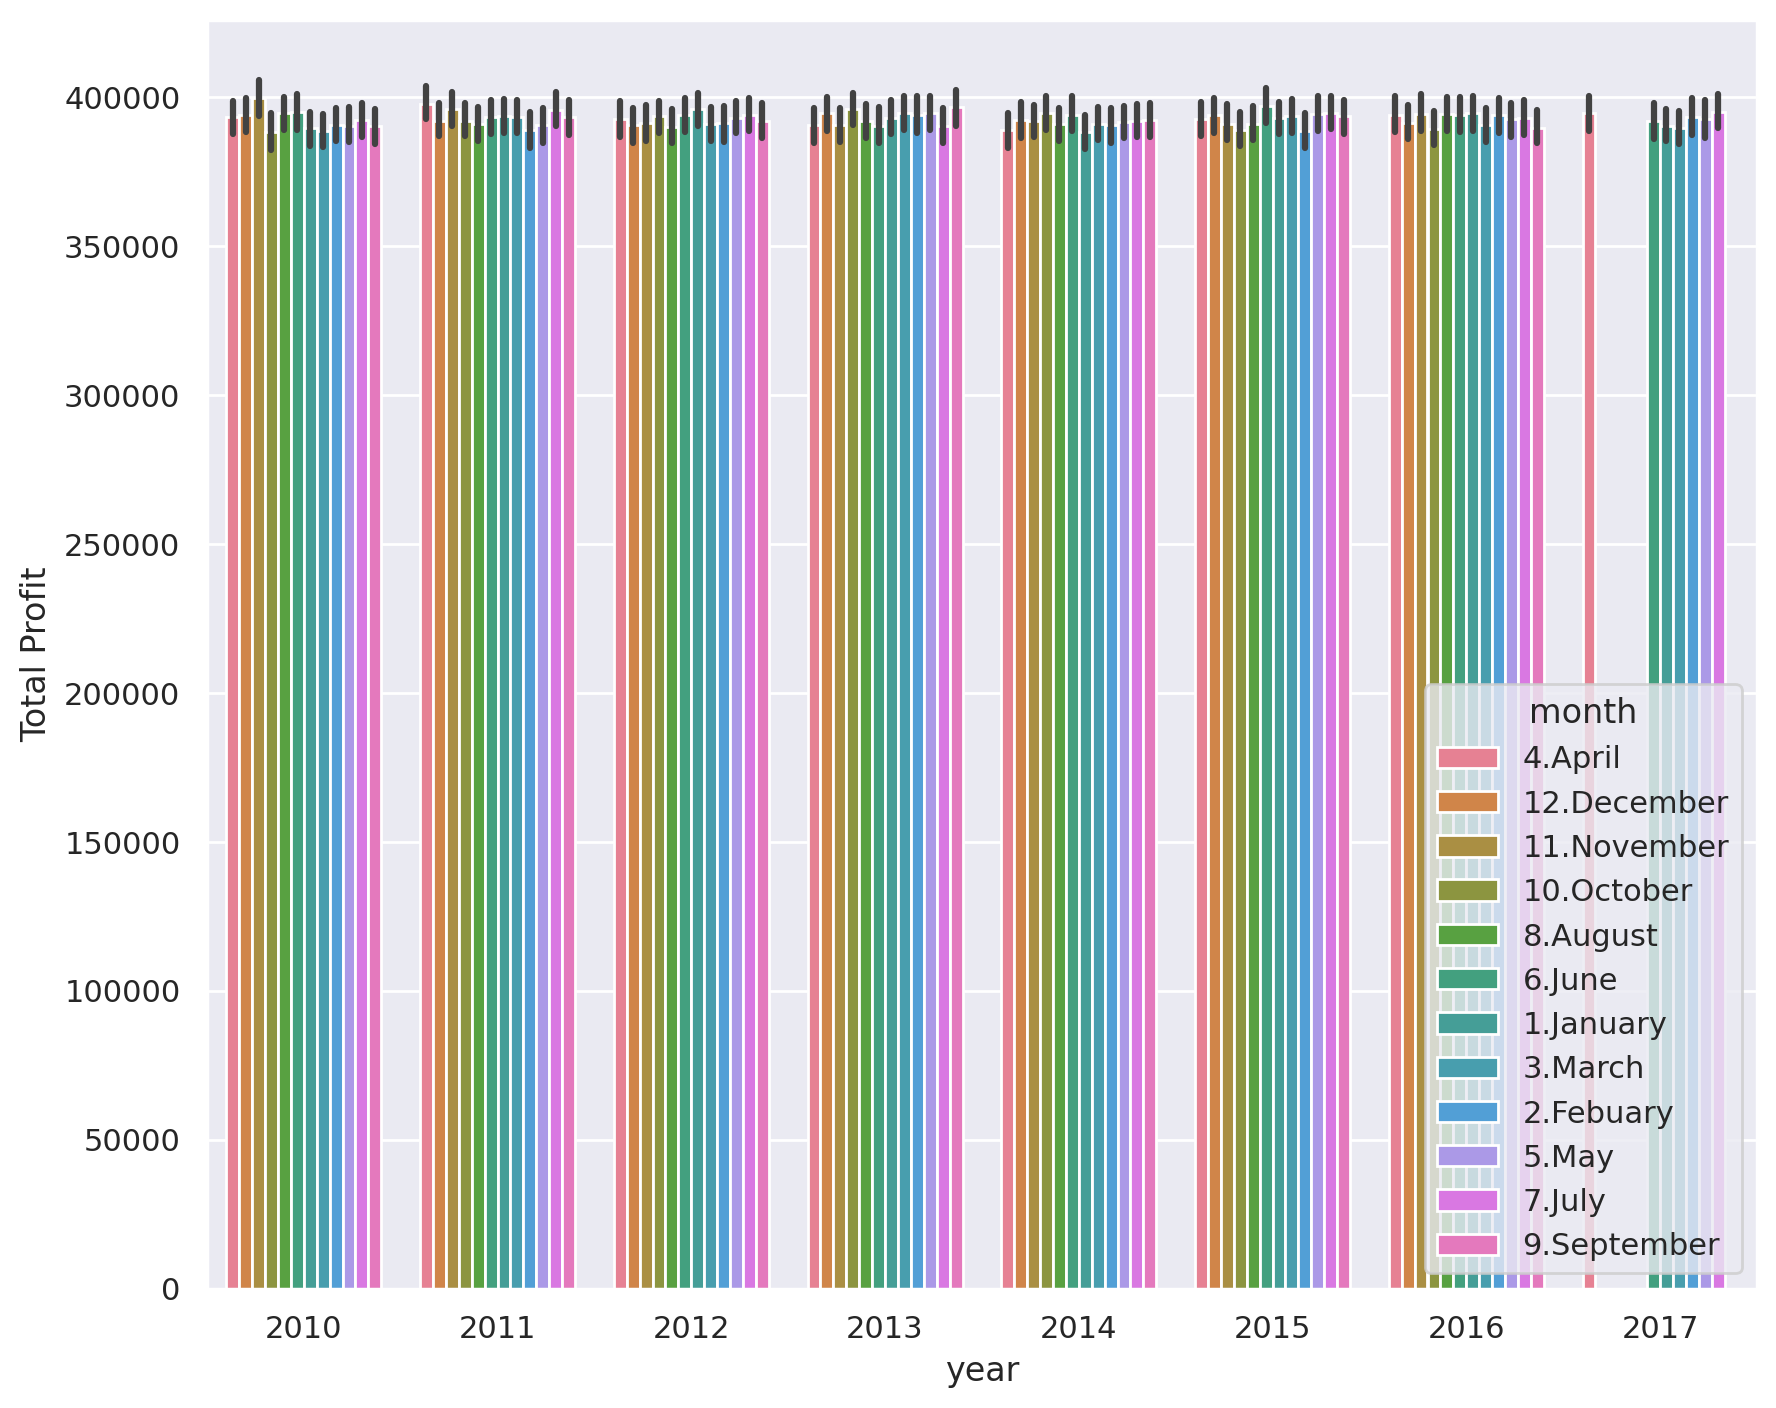

In [ ]:
sns.barplot(x = "year", y = "Total Profit", hue = "month",data = data)

In [ ]:
#สร้างตัวแปรที่ชื่อ margin_top10
margin_top10 = data.sort_values("%margin", ascending = False).head(10)
margin_top10

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision,year,month
1499978,Australia and Oceania,Nauru,Clothes,Online,C,1/24/2013,133836066,2/19/2013,3921,109.28,35.84,428486.88,140528.64,287958.24,67.2,good,2013,1.January
20,Australia and Oceania,Papua New Guinea,Clothes,Offline,L,6/20/2011,647164094,7/14/2011,9092,109.28,35.84,993573.76,325857.28,667716.48,67.2,good,2011,6.June
19,Australia and Oceania,Papua New Guinea,Clothes,Offline,L,6/20/2011,647164094,7/14/2011,9092,109.28,35.84,993573.76,325857.28,667716.48,67.2,good,2011,6.June
1499956,Middle East and North Africa,Syria,Clothes,Online,M,4/13/2011,565764844,4/26/2011,1245,109.28,35.84,136053.60,44620.80,91432.80,67.2,good,2011,4.April
1499945,Sub-Saharan Africa,Lesotho,Clothes,Online,L,1/8/2013,731564843,1/12/2013,5149,109.28,35.84,562682.72,184540.16,378142.56,67.2,good,2013,1.January
1499939,Europe,Bosnia and Herzegovina,Clothes,Offline,M,10/30/2016,866032350,12/2/2016,7072,109.28,35.84,772828.16,253460.48,519367.68,67.2,good,2016,10.October
1499935,Central America and the Caribbean,Haiti,Clothes,Online,M,10/15/2015,770236289,10/16/2015,8889,109.28,35.84,971389.92,318581.76,652808.16,67.2,good,2015,10.October
1499924,Sub-Saharan Africa,South Africa,Clothes,Online,M,12/24/2015,329669511,1/5/2016,5389,109.28,35.84,588909.92,193141.76,395768.16,67.2,good,2015,12.December
1499923,North America,Canada,Clothes,Online,H,6/2/2011,821478927,7/17/2011,2724,109.28,35.84,297678.72,97628.16,200050.56,67.2,good,2011,6.June
1499911,Asia,Turkmenistan,Clothes,Offline,L,10/28/2015,572187983,11/13/2015,1994,109.28,35.84,217904.32,71464.96,146439.36,67.2,good,2015,10.October


<Axes: xlabel='Country', ylabel='Total Revenue'>

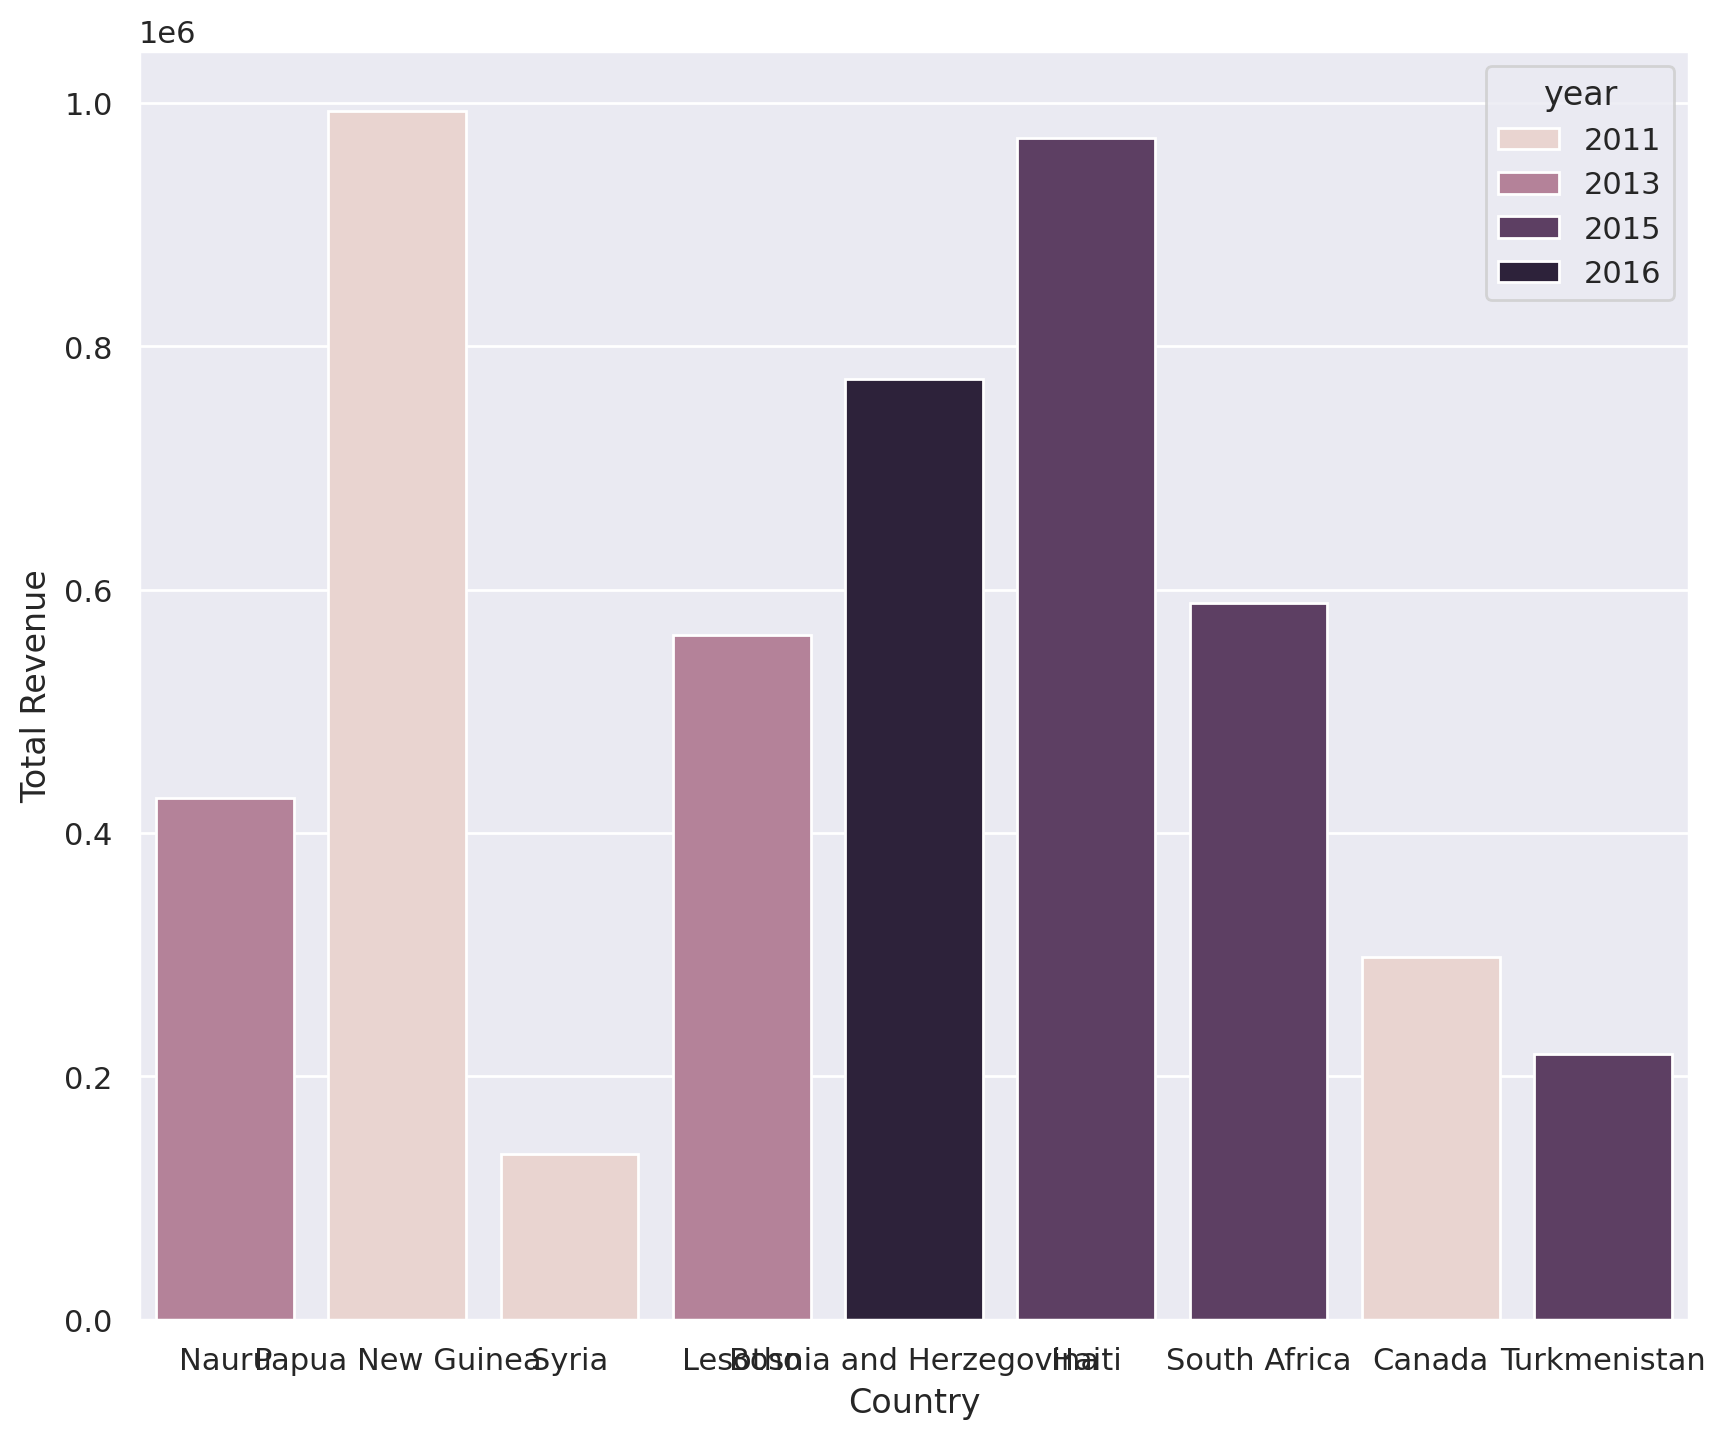

In [ ]:
#ลอง plot อีกรอบ จะเห็นว่าข้อมูลดูง่ายขึ้นเยอะเลย
sns.barplot(x = "Country", y = "Total Revenue",hue = "year",data = margin_top10)


In [ ]:
margin_top10["Total Revenue"]

,Total Revenue
1499978,428486.88
20,993573.76
19,993573.76
1499956,136053.60
1499945,562682.72
1499939,772828.16
1499935,971389.92
1499924,588909.92
1499923,297678.72
1499911,217904.32


In [ ]:
#ต่อมา เราจะมาทำ pie chart กัน ขั้นแรกเรากำหนดสีก่อน
colors = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue']

([<matplotlib.patches.Wedge at 0x7c640b554590>,
 [Text(-0.24621501398191709, 1.0720905590899887, 'Australia and Oceania'),
  Text(-0.910437090242708, 0.6173364598907077, 'Australia and Oceania'),
  Text(-0.9899856178479131, -0.47950857808206737, 'Australia and Oceania'),
  Text(-0.5509594365612539, -0.9520733686350573, 'Middle East and North Africa'),
  Text(-0.17143035863223785, -1.0865595391598302, 'Sub-Saharan Africa'),
  Text(0.5722501854758593, -0.9394305324093127, 'Europe'),
  Text(1.0939701701770133, -0.1150185496469016, 'Central America and the Caribbean'),
  Text(0.8289595051351049, 0.7230671745046668, 'Sub-Saharan Africa'),
  Text(0.4145728916642578, 1.0188863123514496, 'North America'),
  Text(0.12600345505189275, 1.092759410536, 'Asia')],
 [Text(-0.13429909853559113, 0.5847766685945393, '7.2%'),
  Text(-0.4966020492232952, 0.33672897812220415, '16.7%'),
  Text(-0.5399921551897707, -0.26155013349930945, '16.7%'),
  Text(-0.3005233290334112, -0.519312746528213, '2.3%'),
  Tex

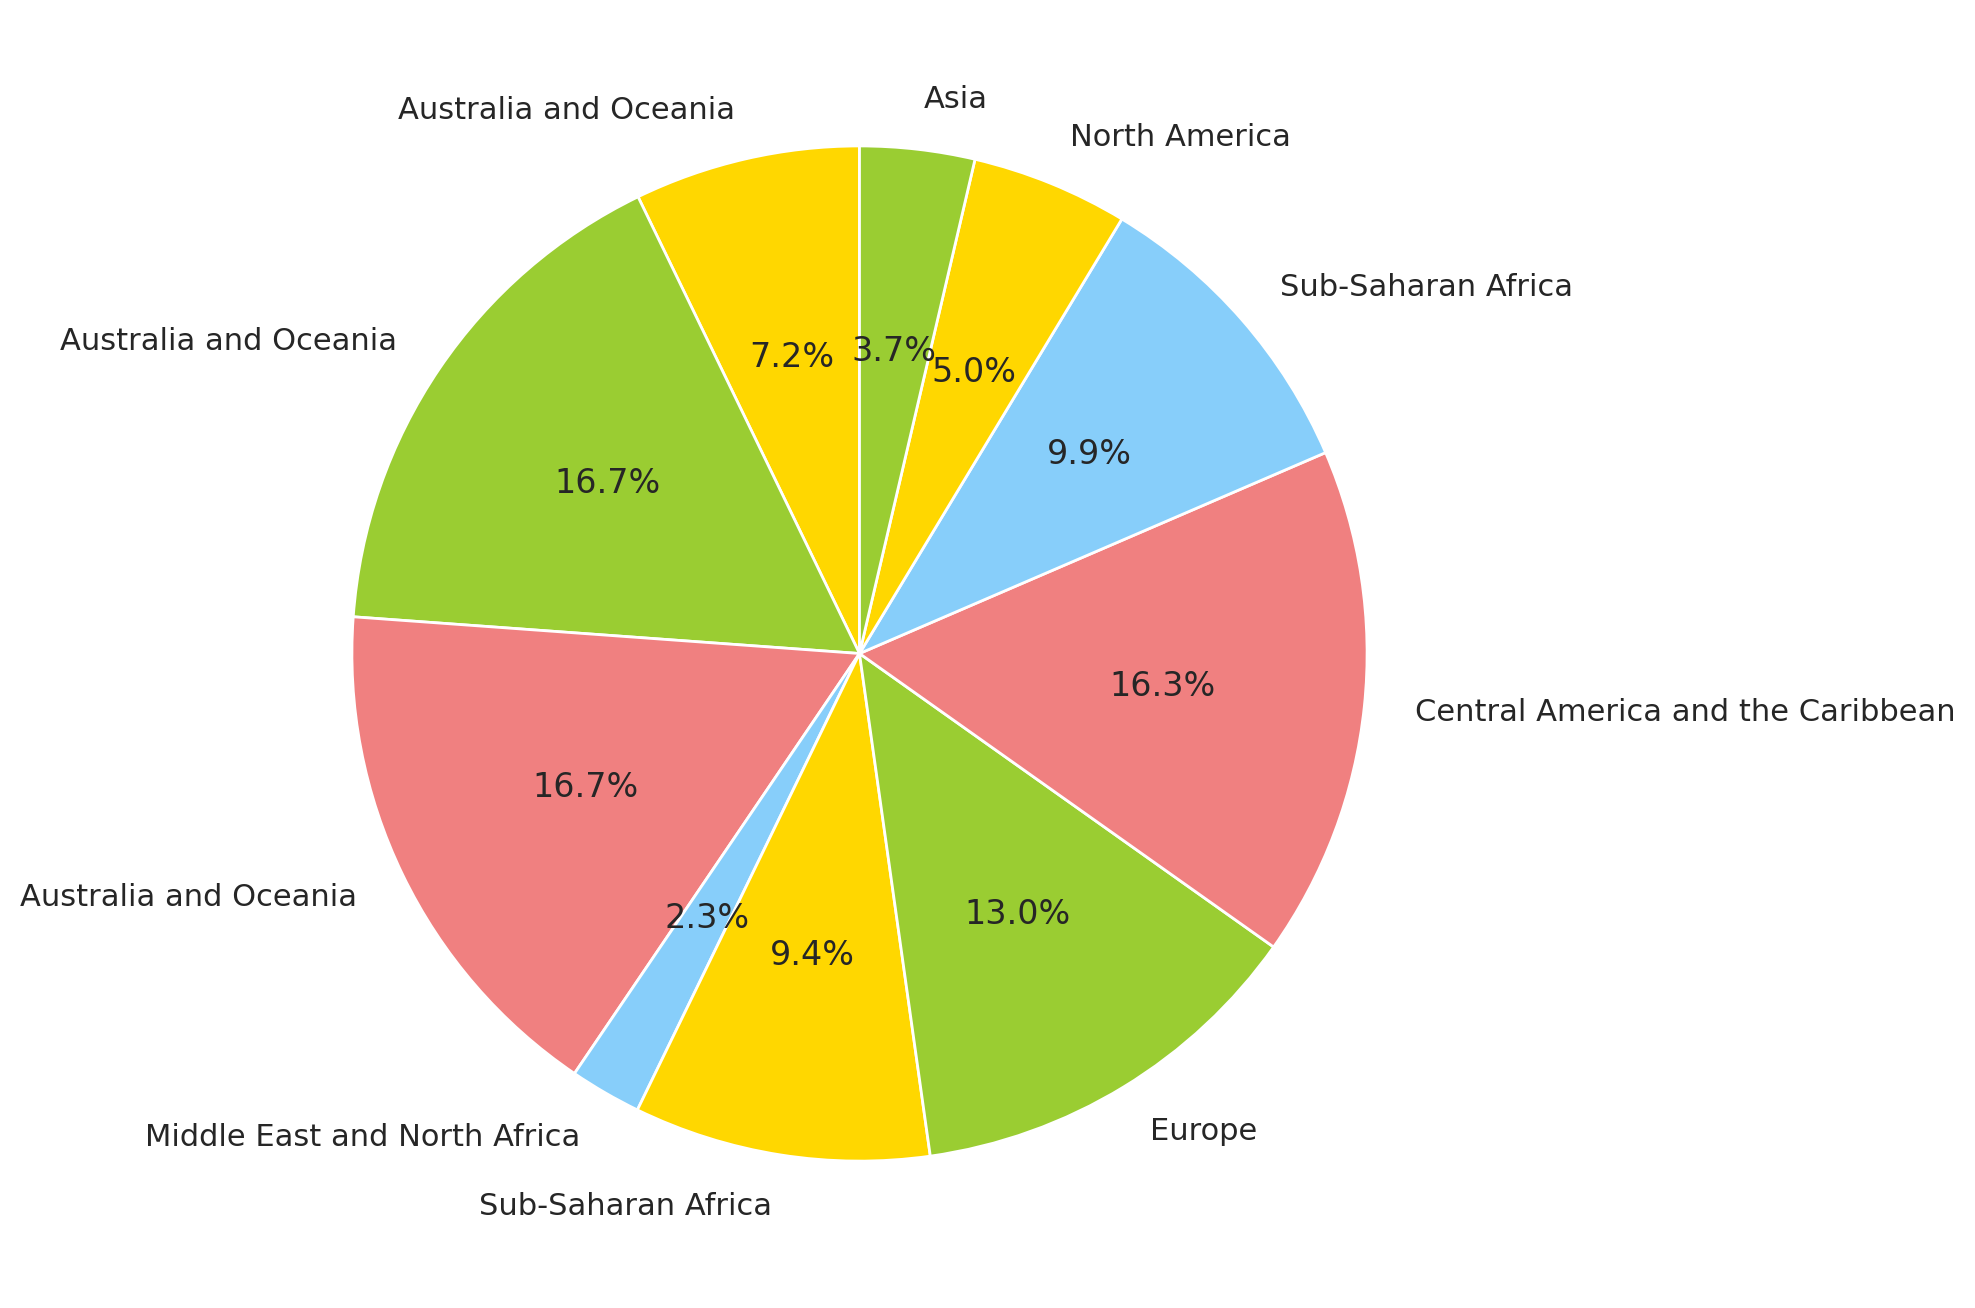

In [ ]:
#Labels คือข้อมูลที่เราจะให้โชว์ คือ "Region" นั่นเอง จะเห็นว่า Middle East สัดส่วนเกิน 50%
plt.pie(margin_top10["Total Revenue"], labels=margin_top10["Region"], colors=colors, startangle=90,autopct='%1.1f%%')


In [ ]:
#Beginning : Machine Learning For bussiness
#มาถึงขั้นตอนสุดท้ายแล้ว เรามาทำ Prediction กันด้วย Linear regression กันครับ

#ก่อนอื่น เราต้อง import library ที่ใช้ในการทำก่อนนะครับ
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
#เช็ค Version
print(f'sklern version : {sklearn.__version__}')


sklern version : 1.6.1


In [ ]:
#เราจะมากำหนด Model กันครับ
model = LinearRegression(n_jobs=-1)
model


LinearRegression(n_jobs=-1)

In [ ]:
#x เราเรียกว่า dependent y คือ independaent และที่เราใช้ [[]] เพราะจะทำเป็น 2D Array
X = data[['Total Revenue','Total Cost']]
y = data['%margin'] #หรือ data.%margin ที่ไม่ใช้เพราะมันติด % นั่นเอง


In [ ]:
model.fit(X,y)

LinearRegression(n_jobs=-1)

In [ ]:
model.score(X,y)

0.5312461953467483

In [ ]:
model.score(X,y)

0.5312461953467483

In [ ]:
model.intercept_
#เขียนสมการทำนายได้ดังนี้ เช่นถ้าอยากทำนาย x = 50000,20000

#หรือพูดเป็นภาษาธุรกิจคือ ถ้ามีรายได้ 50,000 ,Cost 20,000 จะได้ค่า %margin จะเป็นเท่าไรนั่นเอง

model.intercept_ + (-3.38013701e-05* 50000)+(-4.75858163e-05*20000)


np.float64(31.343730852384358)

In [ ]:
#จะได้คำตอบออกมาแล้ว แต่การเขียนยาวๆแบบนี้มันค่อนข้างยุ่งยาก sklearn มีตัวช่วย เขียนดังนี้

#เซลล์โค้ด <undefined>
# %% [code]
model.predict([[50000,20000]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([34.72386869])

In [ ]:
#ถ้าอยากทำนาย 2 ตัวแปรล่ะ
model.predict([[50000,20000],[70000,60000]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([34.72386869, 33.4964627 ])

In [ ]:
#ต่อมา Predict จากข้อมูลกันเลย
y_pred = model.predict(data[["Total Revenue","Total Cost"]]) #อันนี้เอา Columns Total มา Predict เลย
y_pred

array([33.96332994, 33.96332994, 43.15375201, ..., 36.77048543,
       39.81258967, 34.41461044])

In [ ]:
#เราสร้าง Columns ใหม่ชื่อว่า y_act คือค่า Actual นั่นเอง เพื่อจะเอามาเทียบกับตัว Model ที่เราทำไว้
y_act = data[["%margin"]]

In [ ]:
#เช็ค Mean Square error กัน
mean_squared_error(y_act, y_pred)

81.06723336341378

In [ ]:
#เช็ค Root Mean Square error กัน แปลว่า ข้อมูลเรา Error +- ไปถึง9.00 เช่น Actual 10 Model ไปทำนาย 1 หรือ 19 เป็นต้น
mean_squared_error(y_act, y_pred) **0.5

9.003734412087786

In [ ]:
#เอา Model มาใส่เลย จะได้ดังนี้
data["model"] = model.predict(data[["Total Revenue","Total Cost"]])
data.head()

,Region,Country,Item_Type,Sales Channel,Order Priority,Order_Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,%margin,dicision,year,month,model
0,Sub-Saharan Africa,South Africa,Fruits,Offline,M,7/27/2012,443368995,7/28/2012,1593,9.33,6.92,14862.69,11023.56,3839.13,25.83,bad,2012,7.July,33.963330
1,Sub-Saharan Africa,South Africa,Fruits,Offline,M,7/27/2012,443368995,7/28/2012,1593,9.33,6.92,14862.69,11023.56,3839.13,25.83,bad,2012,7.July,33.963330
2,Middle East and North Africa,Morocco,Clothes,Online,M,9/14/2013,667593514,10/19/2013,4611,109.28,35.84,503890.08,165258.24,338631.84,67.20,good,2013,9.September,43.153752
3,Middle East and North Africa,Morocco,Clothes,Online,M,9/14/2013,667593514,10/19/2013,4611,109.28,35.84,503890.08,165258.24,338631.84,67.20,good,2013,9.September,43.153752
4,Australia and Oceania,Papua New Guinea,Meat,Offline,M,5/15/2015,940995585,6/4/2015,360,421.89,364.69,151880.40,131288.40,20592.00,13.56,bad,2015,5.May,32.871816


In [ ]:
#เราจะเอาตัวอย่างข้อมูล 1000 ตัวอย่างแบบเรียงจากมากไปน้อย
margin_top1000_model = data.sort_values("%margin", ascending = False).head(1000)


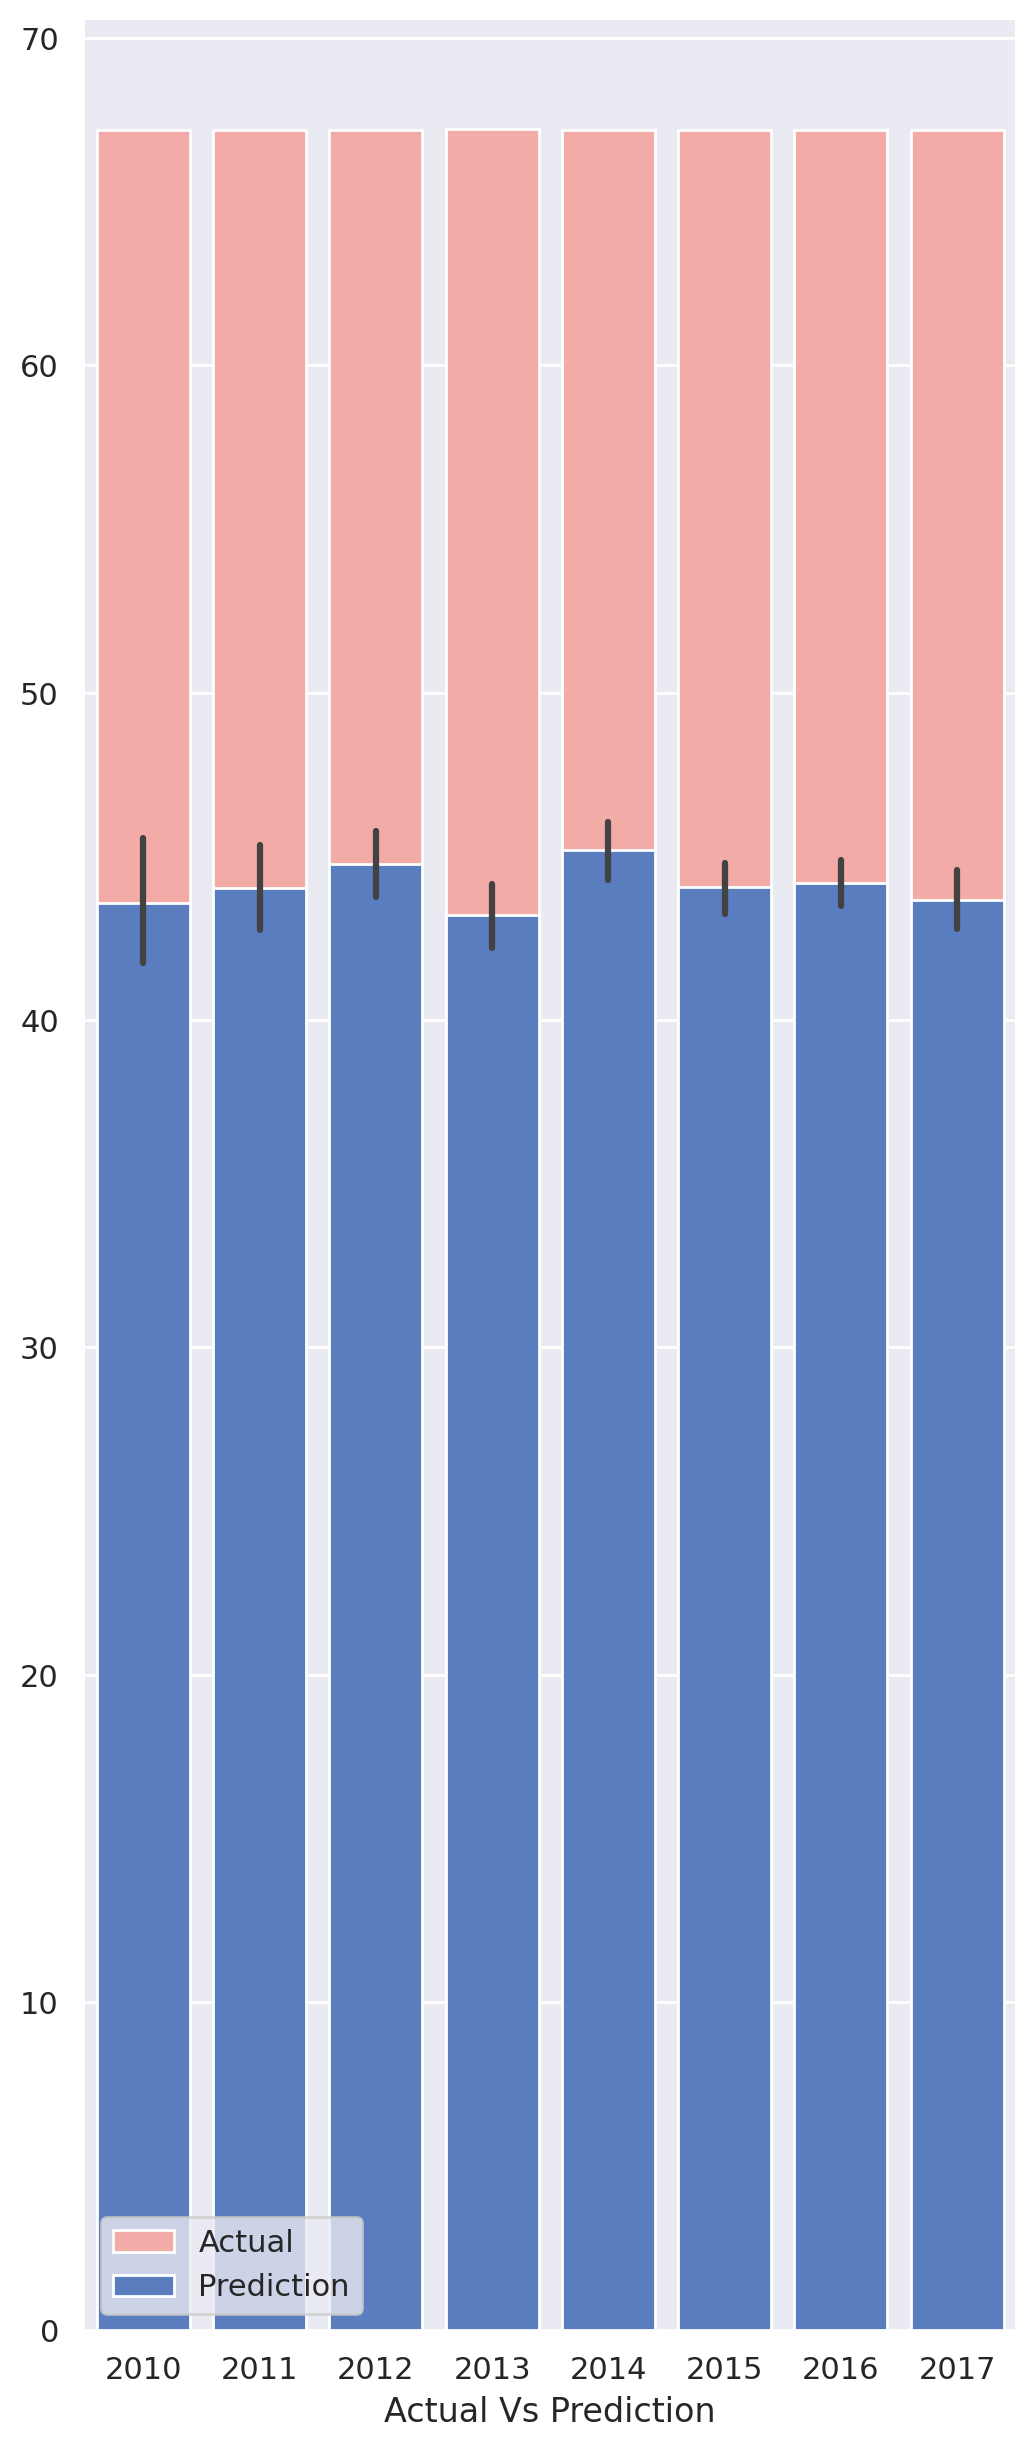

In [ ]:
# Plot 2 กราฟคือ Model vs Actual ซึ่งสีพาสเทลคือ Actual และ Prediction คือ สีทึบ
f, ax = plt.subplots(figsize=(6, 15))
#Graph แรก Actual
sns.set_color_codes("pastel")
sns.barplot(x="year", y="%margin", data=margin_top1000_model,
            label="Actual", color="r")

#Graph สอง Model ที่ทำนายได้
sns.set_color_codes("muted")
sns.barplot(x="year", y="model", data=margin_top1000_model,
            label="Prediction", color="b")

# Add a legend and informative axis label
ax.set(ylabel="",
       xlabel="Actual Vs Prediction")
sns.despine(left=True, bottom=True)
